In [1]:
# Portable project paths (works across computers and working directories)
from pathlib import Path

def find_project_root(marker_dir='CrisisMMD_v2.0'):
    cwd = Path.cwd().resolve()
    home = Path.home().resolve()

    # 1) Fast checks: current path and its parents
    for candidate in [cwd, *cwd.parents]:
        if (candidate / marker_dir).is_dir():
            return candidate

    # 2) Wider checks: common developer roots
    search_roots = [home / 'Projects', home / 'Desktop', home]
    for root in search_roots:
        if not root.exists():
            continue
        direct = root / marker_dir
        if direct.is_dir():
            return root

    # 3) Fallback recursive search (first hit wins)
    for root in search_roots:
        if not root.exists():
            continue
        try:
            hit = next(root.rglob(marker_dir), None)
            if hit and hit.is_dir():
                return hit.parent
        except Exception:
            continue

    raise FileNotFoundError(
        f"Could not find '{marker_dir}' from cwd={cwd}."
    )

PROJECT_ROOT = find_project_root()
CRISIS_ROOT = PROJECT_ROOT / 'CrisisMMD_v2.0'
ANNOTATIONS_DIR = CRISIS_ROOT / 'annotations'

print('Working directory:', Path.cwd())
print('Project root:', PROJECT_ROOT)
print('Annotations dir exists:', ANNOTATIONS_DIR.exists())

Working directory: C:\Users\ynjis\Downloads\crisisMMDDataSet
Project root: C:\Users\ynjis\Downloads\crisisMMDDataSet
Annotations dir exists: True


In [2]:
#Import libraries
import pandas as pd
from PIL import Image
import matplotlib.pyplot as plt
import os
import json
import seaborn as sns
import imagehash
from itertools import combinations


In [3]:
# Reading dataset
if 'ANNOTATIONS_DIR' not in globals():
    from pathlib import Path
    cwd = Path.cwd().resolve()
    home = Path.home().resolve()

    annotations_dir = None
    for candidate in [cwd, *cwd.parents]:
        probe = candidate / 'CrisisMMD_v2.0' / 'annotations'
        if probe.is_dir():
            annotations_dir = probe
            break

    if annotations_dir is None:
        for root in [home / 'Projects', home]:
            if not root.exists():
                continue
            hit = next(root.rglob('CrisisMMD_v2.0'), None)
            if hit and (hit / 'annotations').is_dir():
                annotations_dir = hit / 'annotations'
                break

    if annotations_dir is None:
        raise FileNotFoundError("Could not auto-locate CrisisMMD_v2.0/annotations")

    ANNOTATIONS_DIR = annotations_dir

df = pd.read_csv(ANNOTATIONS_DIR / 'california_wildfires_final_data.tsv', sep='\t')

df.head(5)

,tweet_id,image_id,text_info,text_info_conf,image_info,image_info_conf,text_human,text_human_conf,image_human,image_human_conf,image_damage,image_damage_conf,tweet_text,image_url,image_path
0,917791044158185473,917791044158185473_0,informative,1.0000,informative,0.6766,other_relevant_information,1.0000,other_relevant_information,0.6766,NaN,NaN,RT @Gizmodo: Wildfires raging through Northern...,http://pbs.twimg.com/media/DLyi_WYVYAApwNg.jpg,data_image/california_wildfires/10_10_2017/917...
1,917791130590183424,917791130590183424_0,informative,1.0000,informative,0.6667,infrastructure_and_utility_damage,1.0000,affected_individuals,0.6667,NaN,NaN,PHOTOS: Deadly wildfires rage in California ht...,http://pbs.twimg.com/media/DLymKm9UMAAu0qw.jpg,data_image/california_wildfires/10_10_2017/917...
2,917791291823591425,917791291823591425_0,informative,0.6813,informative,1.0000,other_relevant_information,0.6813,infrastructure_and_utility_damage,1.0000,severe_damage,1.0,RT @Cal_OES: PLS SHARE: Weâ€™re capturing wild...,http://pbs.twimg.com/media/DLudaaZV4AAjT7x.jpg,data_image/california_wildfires/10_10_2017/917...
3,917791291823591425,917791291823591425_1,informative,0.6813,not_informative,1.0000,other_relevant_information,0.6813,not_humanitarian,1.0000,NaN,NaN,RT @Cal_OES: PLS SHARE: Weâ€™re capturing wild...,http://pbs.twimg.com/media/DLudaZXUMAABAEZ.jpg,data_image/california_wildfires/10_10_2017/917...
4,917792092100988929,917792092100988929_0,informative,0.6727,informative,0.6612,other_relevant_information,0.6727,infrastructure_and_utility_damage,0.6612,severe_damage,1.0,RT @TIME: California's raging wildfires as you...,http://pbs.twimg.com/media/DLwNe-NXUAE0XCw.jpg,data_image/california_wildfires/10_10_2017/917...


In [4]:
# merged all tsv file into dataframe with extra label "disaster_type" for better preprocessing
if 'CRISIS_ROOT' not in globals():
    from pathlib import Path
    cwd = Path.cwd().resolve()
    home = Path.home().resolve()

    crisis_root = None
    for candidate in [cwd, *cwd.parents]:
        probe = candidate / 'CrisisMMD_v2.0'
        if probe.is_dir():
            crisis_root = probe
            break

    if crisis_root is None:
        for root in [home / 'Projects', home]:
            if not root.exists():
                continue
            hit = next(root.rglob('CrisisMMD_v2.0'), None)
            if hit and hit.is_dir():
                crisis_root = hit
                break

    if crisis_root is None:
        raise FileNotFoundError("Could not auto-locate CrisisMMD_v2.0")

    CRISIS_ROOT = crisis_root

base_path = str(CRISIS_ROOT)
annotations_dir = os.path.join(base_path, 'annotations')

all_dataframes = []

for filename in os.listdir(annotations_dir):
    if filename.endswith('.tsv') and not filename.startswith('._'):
        file_path = os.path.join(annotations_dir, filename)
        
        temp_df = pd.read_csv(file_path, sep='\t')
        
        disaster_label = filename.replace('_final_data.tsv', '')
        temp_df['disaster_type'] = disaster_label
        
        all_dataframes.append(temp_df)

master_df = pd.concat(all_dataframes, ignore_index=True)

print(f"Total rows merged: {len(master_df)}")
print(master_df['disaster_type'].value_counts())

Total rows merged: 18082
disaster_type
hurricane_maria         4556
hurricane_irma          4504
hurricane_harvey        4434
california_wildfires    1589
mexico_earthquake       1380
srilanka_floods         1022
iraq_iran_earthquake     597
Name: count, dtype: int64


In [5]:
master_df.head(5)

,tweet_id,image_id,text_info,text_info_conf,image_info,image_info_conf,text_human,text_human_conf,image_human,image_human_conf,image_damage,image_damage_conf,tweet_text,image_url,image_path,disaster_type
0,917791044158185473,917791044158185473_0,informative,1.0000,informative,0.6766,other_relevant_information,1.0000,other_relevant_information,0.6766,NaN,NaN,RT @Gizmodo: Wildfires raging through Northern...,http://pbs.twimg.com/media/DLyi_WYVYAApwNg.jpg,data_image/california_wildfires/10_10_2017/917...,california_wildfires
1,917791130590183424,917791130590183424_0,informative,1.0000,informative,0.6667,infrastructure_and_utility_damage,1.0000,affected_individuals,0.6667,NaN,NaN,PHOTOS: Deadly wildfires rage in California ht...,http://pbs.twimg.com/media/DLymKm9UMAAu0qw.jpg,data_image/california_wildfires/10_10_2017/917...,california_wildfires
2,917791291823591425,917791291823591425_0,informative,0.6813,informative,1.0000,other_relevant_information,0.6813,infrastructure_and_utility_damage,1.0000,severe_damage,1.0,RT @Cal_OES: PLS SHARE: Weâ€™re capturing wild...,http://pbs.twimg.com/media/DLudaaZV4AAjT7x.jpg,data_image/california_wildfires/10_10_2017/917...,california_wildfires
3,917791291823591425,917791291823591425_1,informative,0.6813,not_informative,1.0000,other_relevant_information,0.6813,not_humanitarian,1.0000,NaN,NaN,RT @Cal_OES: PLS SHARE: Weâ€™re capturing wild...,http://pbs.twimg.com/media/DLudaZXUMAABAEZ.jpg,data_image/california_wildfires/10_10_2017/917...,california_wildfires
4,917792092100988929,917792092100988929_0,informative,0.6727,informative,0.6612,other_relevant_information,0.6727,infrastructure_and_utility_damage,0.6612,severe_damage,1.0,RT @TIME: California's raging wildfires as you...,http://pbs.twimg.com/media/DLwNe-NXUAE0XCw.jpg,data_image/california_wildfires/10_10_2017/917...,california_wildfires


Tweet Index: 45 | Event: california_wildfires
TEXT: RT @monizcardozo: California wildfires: Residents find devastation in Santa Rosa https://t.co/3fuGJ5lW3t https://t.co/hNuXFATeh8
LABEL (Text): other_relevant_information
url: http://pbs.twimg.com/media/DLy5u7IVwAAaO3e.jpg
path: data_image/california_wildfires/10_10_2017/917815168825995264_0.jpg
imaqge hash: dbb099e39597e6809d280a20d9c776f1
LABEL (Image): vehicle_damage





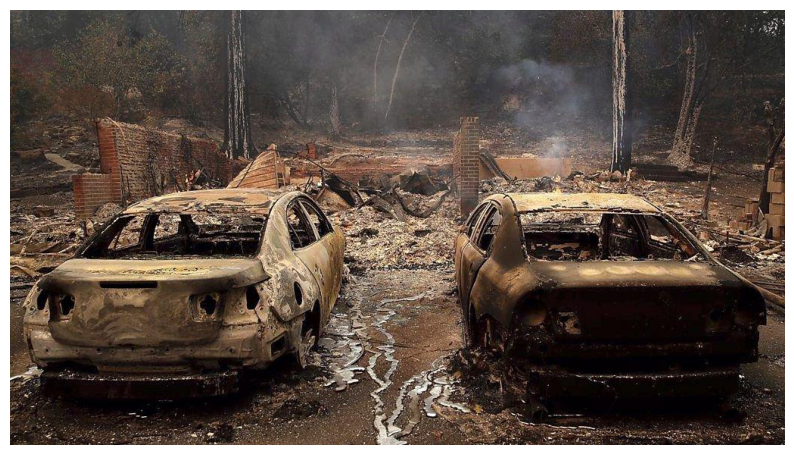

In [6]:
#Display text and tweet image
import hashlib

def display_tweet(df, index):

    if index >= len(df):
        print("Index out of range!")
        return

    row = df.iloc[index]
    
    tweet_text = row['tweet_text']
    img_rel_path = row['image_path']
    
    full_img_path = os.path.join(base_path, img_rel_path)

    def get_image_hash(fname):
        hash_md5 = hashlib.md5()
        try:
            with open(fname, "rb") as f:
                for chunk in iter(lambda: f.read(4096), b""):
                    hash_md5.update(chunk)
            return hash_md5.hexdigest()
        except FileNotFoundError:
            return None

    image_hash = get_image_hash(full_img_path)
    

    print(f"Tweet Index: {index} | Event: {row['disaster_type']}")
    print(f"TEXT: {tweet_text}")
    print(f"LABEL (Text): {row['text_human']}")
    print(f"url: {row['image_url']}")
    print(f"path: {row['image_path']}")
    print(f"imaqge hash: {image_hash}")
    print(f"LABEL (Image): {row['image_human']}")
    print("\n\n")
    
    if os.path.exists(full_img_path):
        img = Image.open(full_img_path)
        plt.figure(figsize=(10, 6))
        plt.imshow(img)
        plt.axis('off')
        plt.show()
    else:
        print(f"Error: image not found at {full_img_path}")

display_tweet(master_df, 45)

In [7]:
df["text_human"].unique()

array(['other_relevant_information', 'infrastructure_and_utility_damage',
       'injured_or_dead_people', 'not_humanitarian',
       'missing_or_found_people',
       'rescue_volunteering_or_donation_effort', 'affected_individuals',
       'vehicle_damage'], dtype=object)

In [8]:
# Tweet Index: 43 | Event: california_wildfires
# TEXT: RT @TheAtlantic: Photos of California's destructive wildfires, via @TheAtlPhoto: https://t.co/mzYsQALqrl https://t.co/bWvczIJa2Z
# LABEL (Text): infrastructure_and_utility_damage
# LABEL (Text): http://pbs.twimg.com/media/DLy7qk8WsAI8aOA.jpg
# LABEL (Text): data_image/california_wildfires/10_10_2017/917815040962695168_1.jpg
# LABEL (Image): vehicle_damage

In [9]:
# Tweet Index: 45 | Event: california_wildfires
# TEXT: RT @monizcardozo: California wildfires: Residents find devastation in Santa Rosa https://t.co/3fuGJ5lW3t https://t.co/hNuXFATeh8
# LABEL (Text): other_relevant_information
# LABEL (Text): http://pbs.twimg.com/media/DLy5u7IVwAAaO3e.jpg
# LABEL (Text): data_image/california_wildfires/10_10_2017/917815168825995264_0.jpg
# LABEL (Image): vehicle_damage


Tweet Index: 45 | Event: california_wildfires
TEXT: RT @monizcardozo: California wildfires: Residents find devastation in Santa Rosa https://t.co/3fuGJ5lW3t https://t.co/hNuXFATeh8
LABEL (Text): other_relevant_information
URL: http://pbs.twimg.com/media/DLy5u7IVwAAaO3e.jpg
Path: data_image/california_wildfires/10_10_2017/917815168825995264_0.jpg
Image Hash: dbb099e39597e6809d280a20d9c776f1
LABEL (Image): vehicle_damage




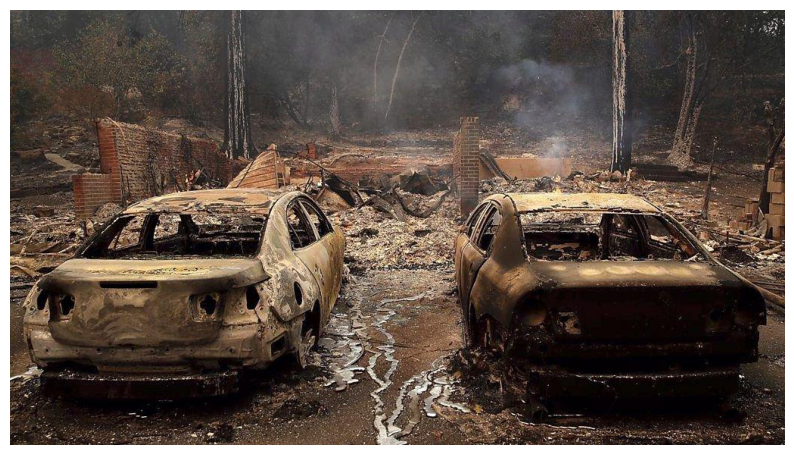

In [10]:
import hashlib

def get_image_hash(fname):
    hash_md5 = hashlib.md5()
    try:
        with open(fname, "rb") as f:
            for chunk in iter(lambda: f.read(4096), b""):
                hash_md5.update(chunk)
        return hash_md5.hexdigest()
    except FileNotFoundError:
        return None

def display_tweet(df, index):
    if index >= len(df):
        print("Index out of range!")
        return

    row = df.iloc[index]
    tweet_text = row['tweet_text']
    img_rel_path = row['image_path']
    
    full_img_path = os.path.join(base_path, img_rel_path)

    image_hash = get_image_hash(full_img_path)

    print(f"Tweet Index: {index} | Event: {row['disaster_type']}")
    print(f"TEXT: {tweet_text}")
    print(f"LABEL (Text): {row['text_human']}")
    print(f"URL: {row['image_url']}")
    print(f"Path: {row['image_path']}")
    print(f"Image Hash: {image_hash}")
    print(f"LABEL (Image): {row['image_human']}")
    print("\n")
    
    if os.path.exists(full_img_path):
        img = Image.open(full_img_path)
        plt.figure(figsize=(10, 6))
        plt.imshow(img)
        plt.axis('off')
        plt.show()
    else:
        print(f"Error: image not found at {full_img_path}")

display_tweet(master_df, 45)

Tweet Index: 43 | Event: california_wildfires
TEXT: RT @TheAtlantic: Photos of California's destructive wildfires, via @TheAtlPhoto: https://t.co/mzYsQALqrl https://t.co/bWvczIJa2Z
LABEL (Text): infrastructure_and_utility_damage
URL: http://pbs.twimg.com/media/DLy7qk8WsAI8aOA.jpg
Path: data_image/california_wildfires/10_10_2017/917815040962695168_1.jpg
Image Hash: 7a273053802f3fa5d462c8b1354bd2f0
LABEL (Image): vehicle_damage




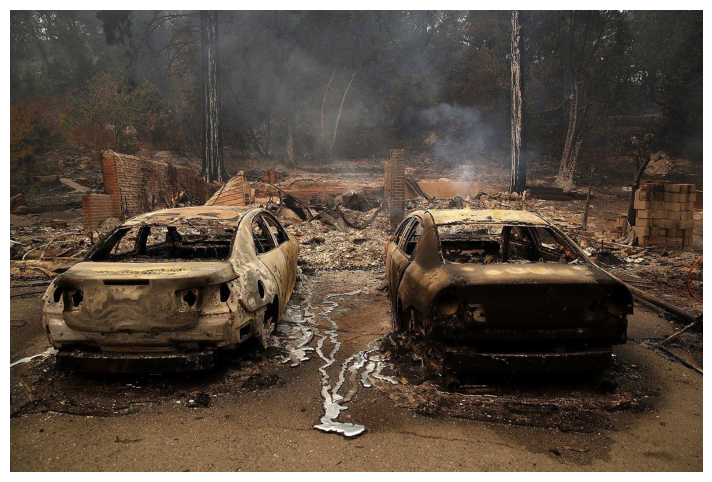

In [11]:
import hashlib

def get_image_hash(fname):
    hash_md5 = hashlib.md5()
    try:
        with open(fname, "rb") as f:
            for chunk in iter(lambda: f.read(4096), b""):
                hash_md5.update(chunk)
        return hash_md5.hexdigest()
    except FileNotFoundError:
        return None

def display_tweet(df, index):
    if index >= len(df):
        print("Index out of range!")
        return

    row = df.iloc[index]
    tweet_text = row['tweet_text']
    img_rel_path = row['image_path']
    
    full_img_path = os.path.join(base_path, img_rel_path)

    image_hash = get_image_hash(full_img_path)

    print(f"Tweet Index: {index} | Event: {row['disaster_type']}")
    print(f"TEXT: {tweet_text}")
    print(f"LABEL (Text): {row['text_human']}")
    print(f"URL: {row['image_url']}")
    print(f"Path: {row['image_path']}")
    print(f"Image Hash: {image_hash}")
    print(f"LABEL (Image): {row['image_human']}")
    print("\n")
    
    if os.path.exists(full_img_path):
        img = Image.open(full_img_path)
        plt.figure(figsize=(10, 6))
        plt.imshow(img)
        plt.axis('off')
        plt.show()
    else:
        print(f"Error: image not found at {full_img_path}")

display_tweet(master_df, 43)

In [12]:
def add_hash_column(df, base_path):
    hashes = []
    for _, row in df.iterrows():
        full_path = os.path.join(base_path, row["image_path"])
        hashes.append(get_image_hash(full_path))
    df["image_hash"] = hashes
    return df

master_df = add_hash_column(master_df, base_path)

# duplicate_hashes = (
#     master_df["image_hash"]
#     .value_counts()
#     .loc[lambda x: x > 1]
# )

# duplicate_df = master_df[
#     master_df["image_hash"].isin(duplicate_hashes.index)
# ]


# print(duplicate_df.head(5)) 
# print(f"Number of duplicate Images: {len(duplicate_df)}")


hash_counts = master_df["image_hash"].value_counts()

duplicate_hashes = hash_counts.loc[lambda x: x > 1]

duplicate_df = master_df[master_df["image_hash"].isin(duplicate_hashes.index)]

hash_dict = (
    duplicate_df.groupby("image_hash")
    .agg(
        count=("image_hash", "size"),
        events=("disaster_type", lambda x: list(x.unique()))
    )
    .to_dict(orient="index")
)

total_images = len(master_df)
unique_hashes_total = len(hash_counts)
num_unique_duplicates = len(duplicate_hashes)
total_duplicate_rows =  len(duplicate_df)

print(f"  Dataset Image Summary")
print(f"Total images in dataset:        {total_images}")
print(f"Total unique images (hashes):   {unique_hashes_total}")
print(f"Unique images that have copies: {num_unique_duplicates}")
print(f"Total rows that are duplicates: {total_duplicate_rows}")


def print_duplicate_hash(n):
    for i, (h, info) in enumerate(hash_dict.items()):
        if i < n:
            print(f"Hash: {h} | Count: {info['count']} | Events: {info['events']}")

print_duplicate_hash(5)

  Dataset Image Summary
Total images in dataset:        18082
Total unique images (hashes):   17777
Unique images that have copies: 181
Total rows that are duplicates: 486
Hash: 0122aaa0c9570986afd109c82d49a032 | Count: 2 | Events: ['iraq_iran_earthquake']
Hash: 018ffe193fd5f977f7066e3714027b10 | Count: 2 | Events: ['hurricane_irma']
Hash: 02cb3fdbe35760a7997d5e7ec4267073 | Count: 2 | Events: ['hurricane_maria']
Hash: 047dfd1d3e2993fe171f2d6f7e9a3fa4 | Count: 33 | Events: ['california_wildfires', 'hurricane_harvey', 'hurricane_irma', 'hurricane_maria', 'iraq_iran_earthquake', 'mexico_earthquake']
Hash: 07f26ecef0d326169f37dfe69826806f | Count: 2 | Events: ['hurricane_harvey']


In [13]:
event_duplicate_counts = duplicate_df.groupby("disaster_type").size().sort_values(ascending=False)

print("Duplicate images per event")
for event, count in event_duplicate_counts.items(): 
    print(f"{event:<30}: {count} duplicate rows")

Duplicate images per event
hurricane_maria               : 115 duplicate rows
hurricane_irma                : 100 duplicate rows
hurricane_harvey              : 92 duplicate rows
california_wildfires          : 71 duplicate rows
mexico_earthquake             : 60 duplicate rows
srilanka_floods               : 28 duplicate rows
iraq_iran_earthquake          : 20 duplicate rows


C:\Users\ynjis\AppData\Local\Temp\ipykernel_5784\665126745.py:7: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend().set_visible(False)


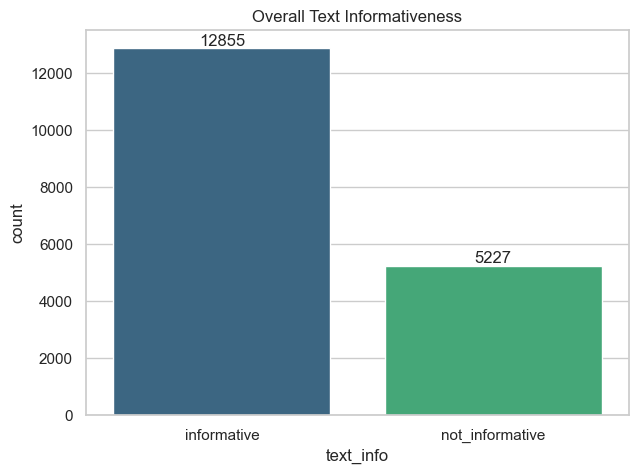

C:\Users\ynjis\AppData\Local\Temp\ipykernel_5784\665126745.py:21: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend().set_visible(False)


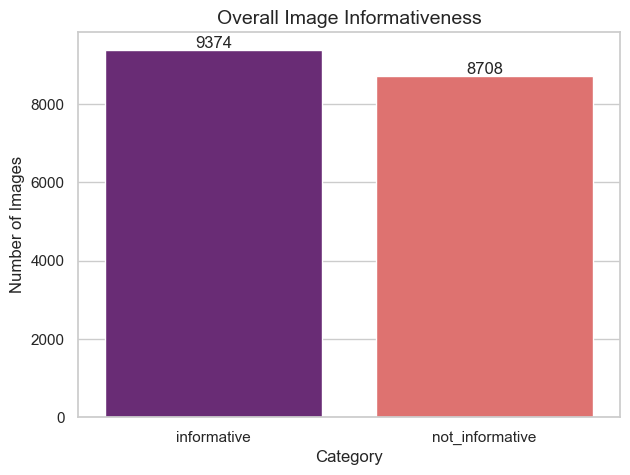

In [14]:
#text informativeness
sns.set_theme(style="whitegrid")

plt.figure(figsize=(7, 5))

ax = sns.countplot(data=master_df, x='text_info', hue='text_info', palette='viridis')
plt.legend().set_visible(False)

for container in ax.containers:
    ax.bar_label(container)

plt.title('Overall Text Informativeness')
plt.show()



#Image  informativesness
plt.figure(figsize=(7, 5))

ax = sns.countplot(data=master_df, x='image_info', hue='image_info', palette='magma')
plt.legend().set_visible(False)

for container in ax.containers:
    ax.bar_label(container)

plt.title('Overall Image Informativeness', fontsize=14)
plt.xlabel('Category')
plt.ylabel('Number of Images')

plt.show()


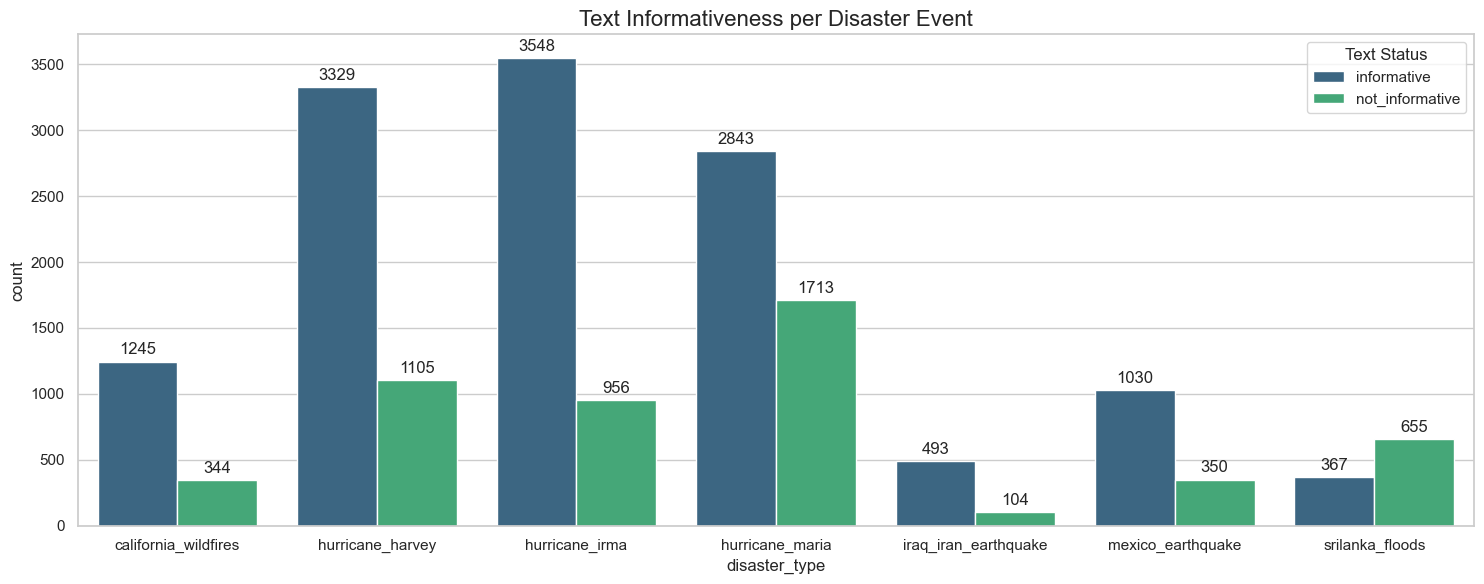

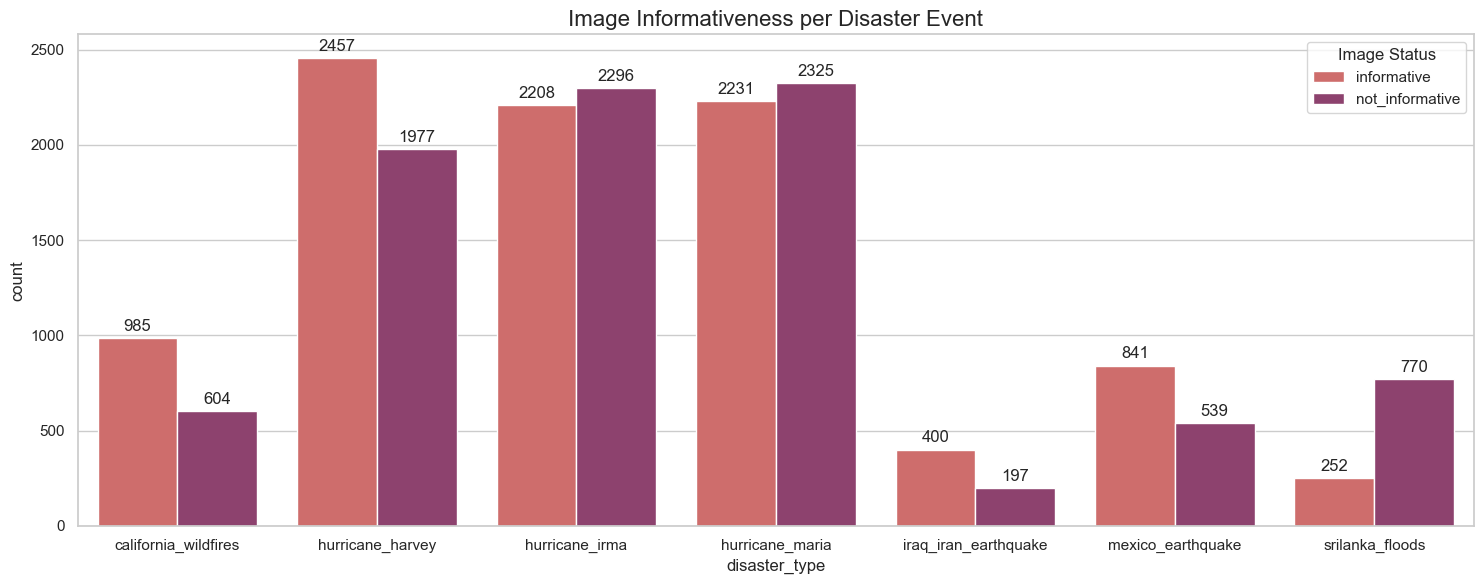

In [15]:

#text informativenss event wise
plt.figure(figsize=(15, 6))

ax = sns.countplot(data=master_df, x='disaster_type', hue='text_info', palette='viridis')

for container in ax.containers:
    ax.bar_label(container, padding=3)

plt.title('Text Informativeness per Disaster Event', fontsize=16)
plt.legend(title='Text Status', loc='upper right')

plt.tight_layout()
plt.show()


# image informativeness based on events
plt.figure(figsize=(15, 6))

ax = sns.countplot(data=master_df, x='disaster_type', hue='image_info', palette='flare')

for container in ax.containers:
    ax.bar_label(container, padding=3)

plt.title('Image Informativeness per Disaster Event', fontsize=16)
plt.legend(title='Image Status', loc='upper right')

plt.tight_layout()
plt.show()

C:\Users\ynjis\AppData\Local\Temp\ipykernel_5784\3627351872.py:11: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend().set_visible(False)


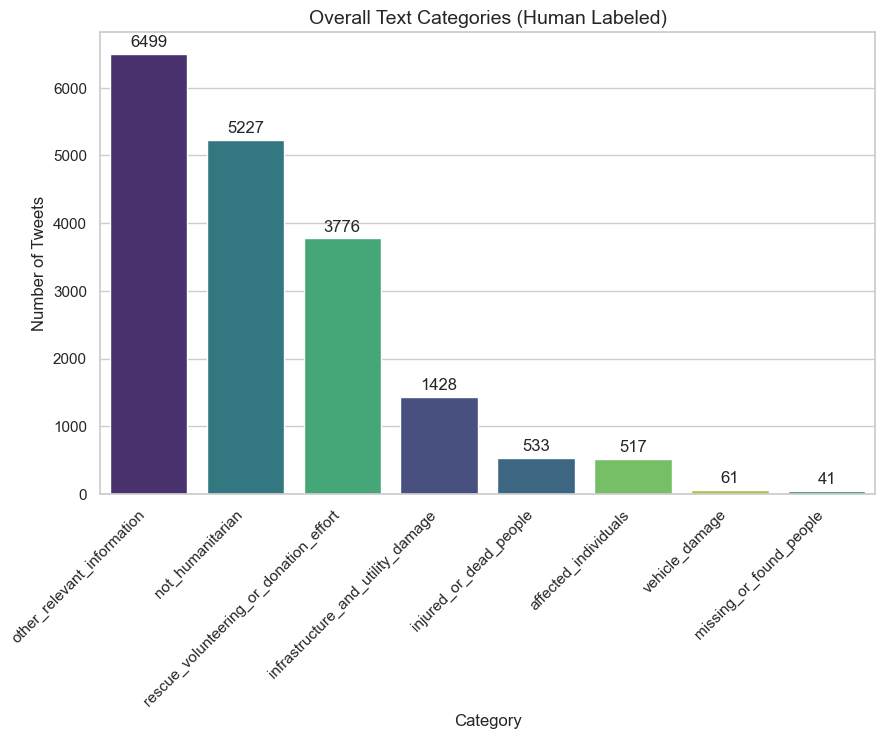

C:\Users\ynjis\AppData\Local\Temp\ipykernel_5784\3627351872.py:36: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend().set_visible(False)


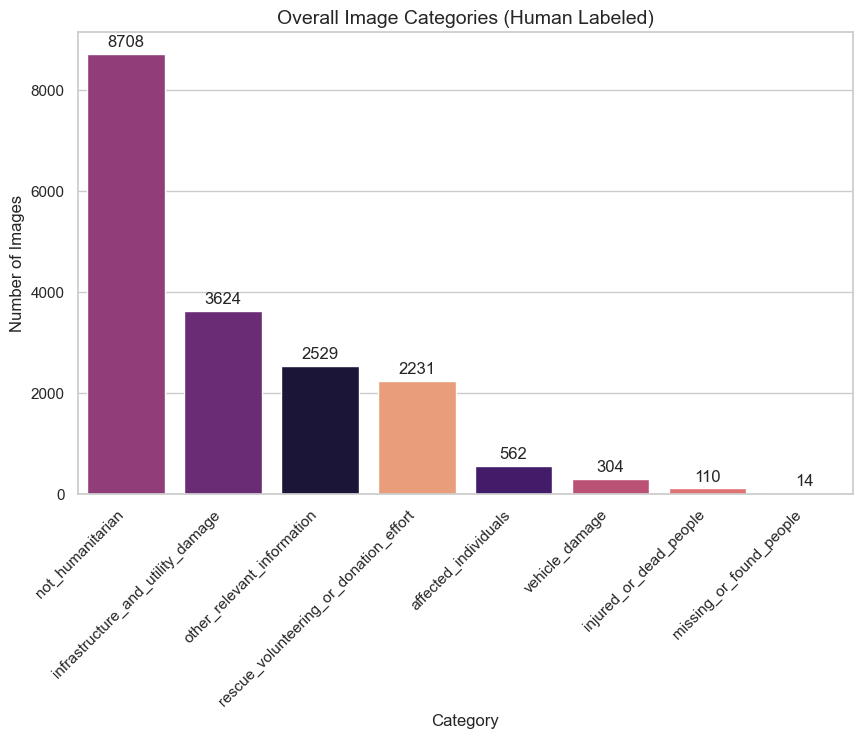

In [16]:
# text human labeled categories
plt.figure(figsize=(10, 6))

ax = sns.countplot(
    data=master_df, 
    x='text_human', 
    hue='text_human', 
    palette='viridis',
    order=master_df['text_human'].value_counts().index
)
plt.legend().set_visible(False)

for container in ax.containers:
    ax.bar_label(container, padding=3)

plt.title('Overall Text Categories (Human Labeled)', fontsize=14)
plt.xlabel('Category')
plt.xticks(rotation=45, ha='right')
plt.ylabel('Number of Tweets')

plt.show()




# Image human labeled categories
plt.figure(figsize=(10, 6))

ax = sns.countplot(
    data=master_df, 
    x='image_human', 
    hue='image_human', 
    palette='magma',
    order=master_df['image_human'].value_counts().index
)
plt.legend().set_visible(False)

for container in ax.containers:
    ax.bar_label(container, padding=3)

plt.title('Overall Image Categories (Human Labeled)', fontsize=14)
plt.xlabel('Category')
plt.xticks(rotation=45, ha='right')
plt.ylabel('Number of Images')

plt.show()


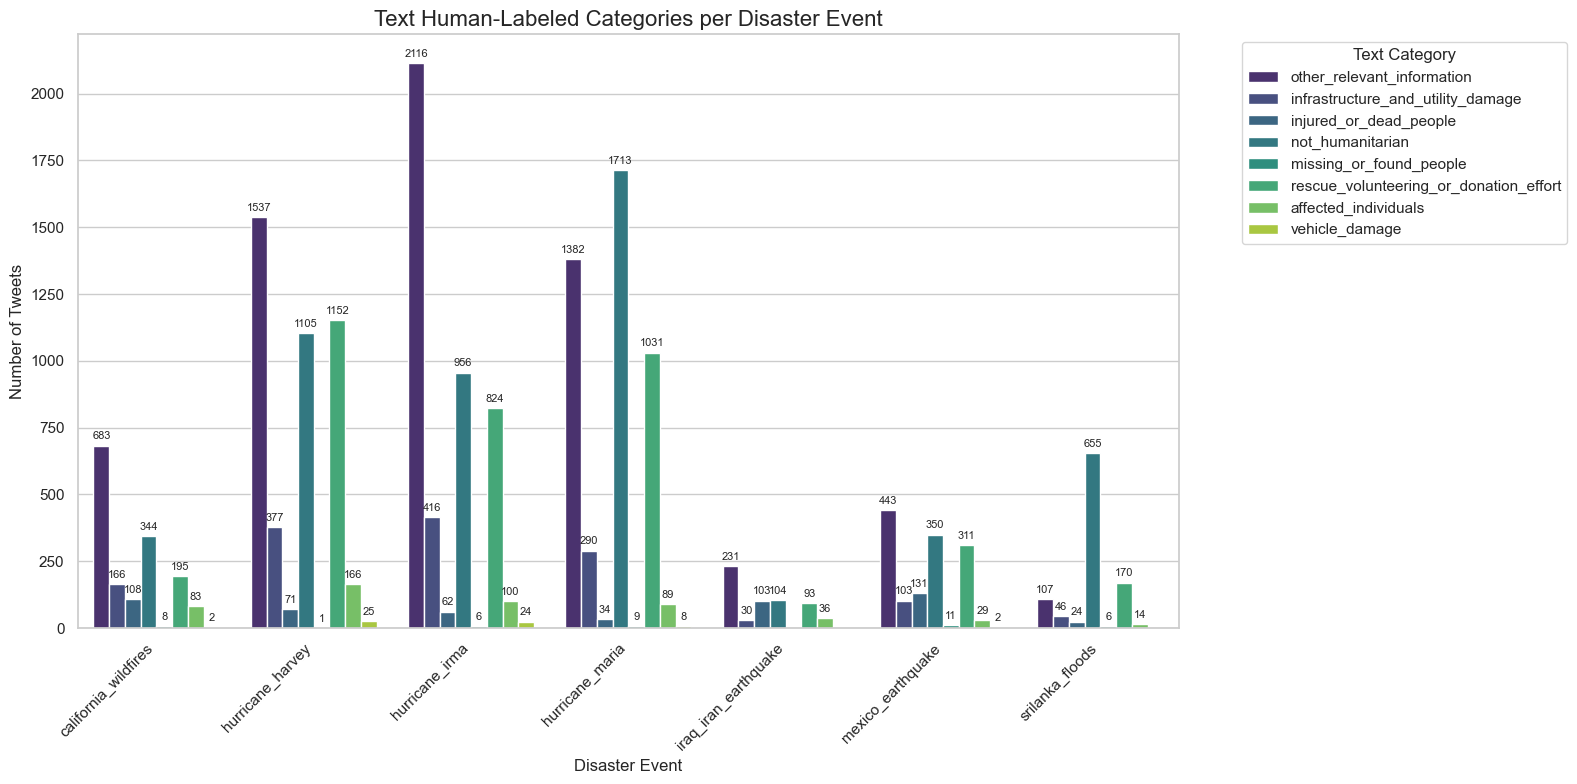

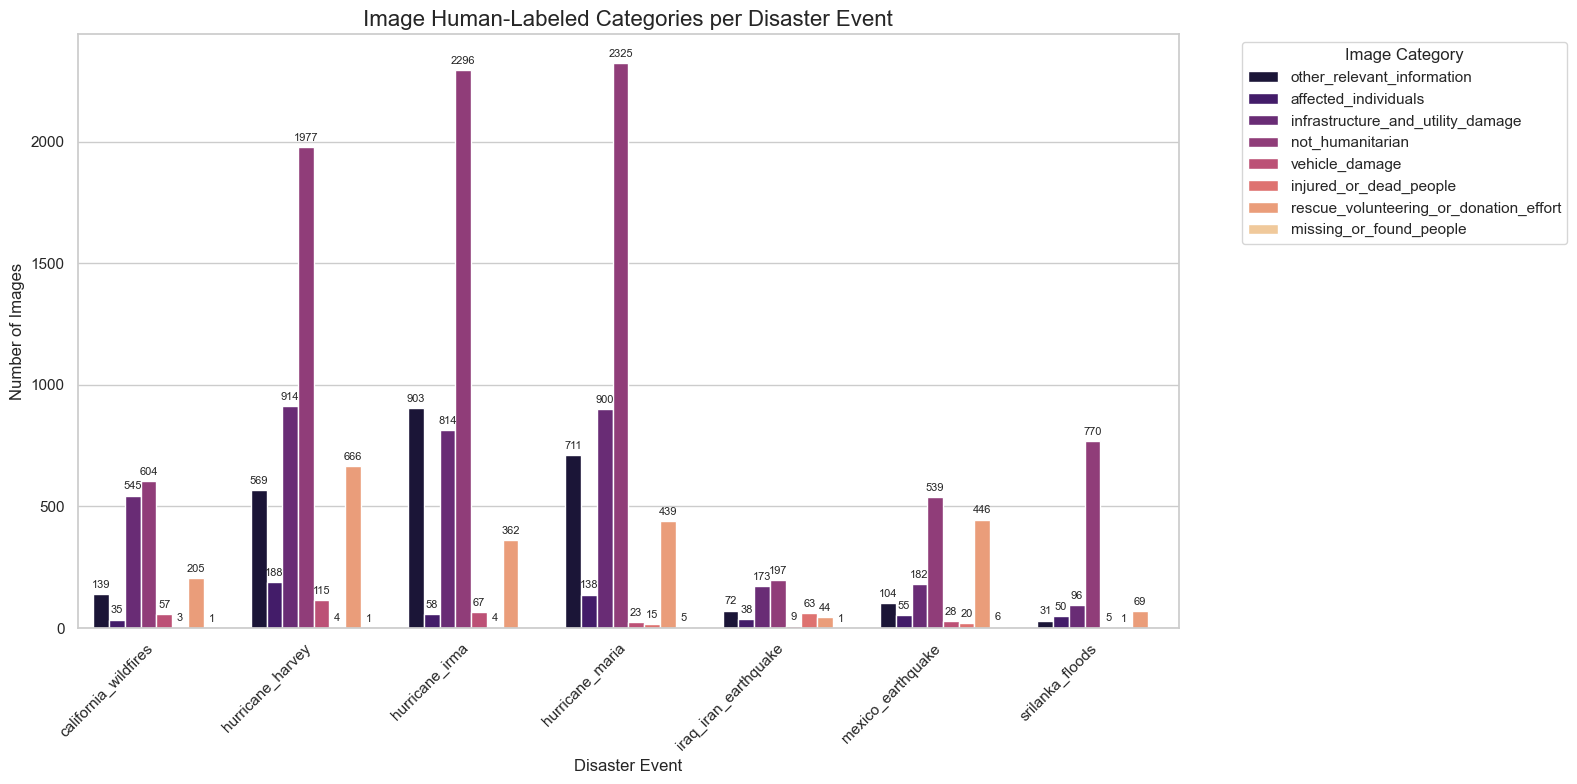

In [17]:
# Text human labeled categories event wise
plt.figure(figsize=(16, 8))

ax = sns.countplot(
    data=master_df, 
    x='disaster_type', 
    hue='text_human', 
    palette='viridis'
)

for container in ax.containers:
    ax.bar_label(container, padding=3, fontsize=8)

plt.title('Text Human-Labeled Categories per Disaster Event', fontsize=16)
plt.xticks(rotation=45, ha='right')
plt.xlabel('Disaster Event')
plt.ylabel('Number of Tweets')

plt.legend(title='Text Category', bbox_to_anchor=(1.05, 1), loc='upper left')

plt.tight_layout()
plt.show()



# Image human labeled categories event wise
plt.figure(figsize=(16, 8))
ax = sns.countplot(
    data=master_df, 
    x='disaster_type', 
    hue='image_human', 
    palette='magma'
)

for container in ax.containers:
    ax.bar_label(container, padding=3, fontsize=8)

plt.title('Image Human-Labeled Categories per Disaster Event', fontsize=16)
plt.xticks(rotation=45, ha='right')
plt.xlabel('Disaster Event')
plt.ylabel('Number of Images')

plt.legend(title='Image Category', bbox_to_anchor=(1.05, 1), loc='upper left')

plt.tight_layout()
plt.show()

C:\Users\ynjis\AppData\Local\Temp\ipykernel_5784\4253298573.py:15: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend().set_visible(False)


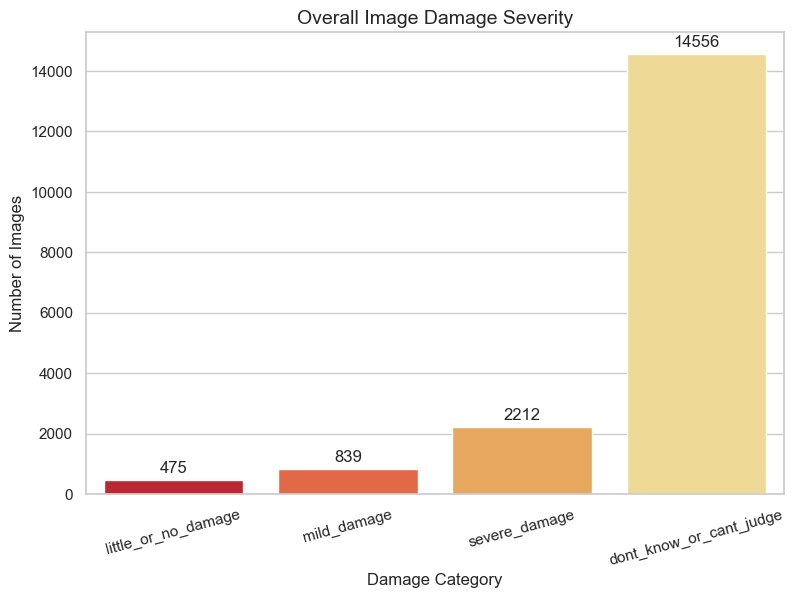

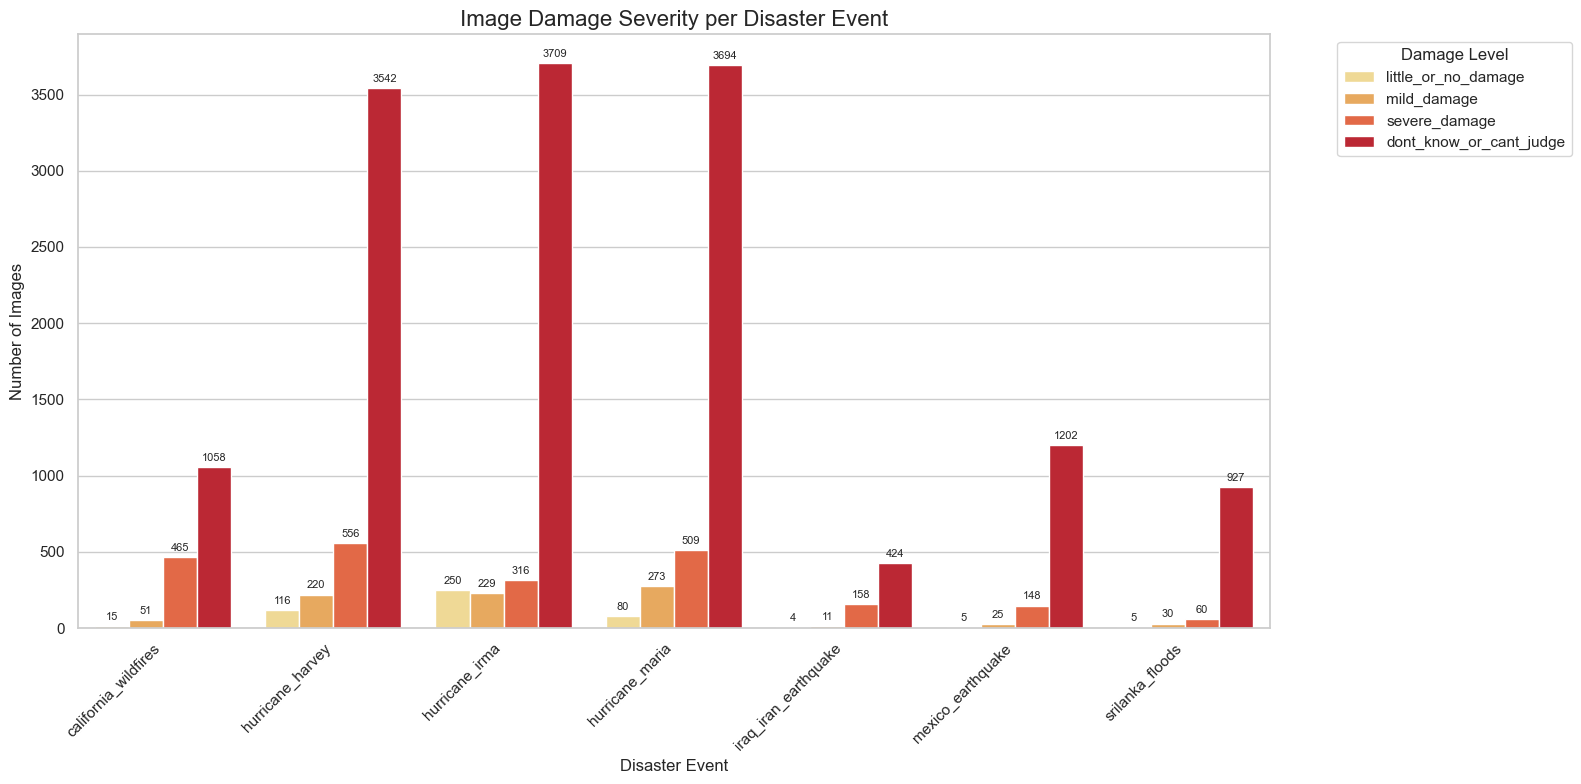

In [18]:
#fill nan with dont know category
master_df['image_damage'] = master_df['image_damage'].fillna('dont_know_or_cant_judge')

damage_order = ['little_or_no_damage', 'mild_damage', 'severe_damage', 'dont_know_or_cant_judge']

plt.figure(figsize=(9, 6))

ax = sns.countplot(
    data=master_df, 
    x='image_damage', 
    hue='image_damage', 
    palette='YlOrRd', 
    order=damage_order
)
plt.legend().set_visible(False)

for container in ax.containers:
    ax.bar_label(container, padding=3)

plt.title('Overall Image Damage Severity', fontsize=14)
plt.xlabel('Damage Category')
plt.ylabel('Number of Images')
plt.xticks(rotation=15)

plt.show()



#image damage severity event wise
plt.figure(figsize=(16, 8))

ax = sns.countplot(
    data=master_df, 
    x='disaster_type', 
    hue='image_damage', 
    hue_order=damage_order,
    palette='YlOrRd'
)

for container in ax.containers:
    ax.bar_label(container, padding=3, fontsize=8)

plt.title('Image Damage Severity per Disaster Event', fontsize=16)
plt.xticks(rotation=45, ha='right')
plt.xlabel('Disaster Event')
plt.ylabel('Number of Images')

plt.legend(title='Damage Level', bbox_to_anchor=(1.05, 1), loc='upper left')

plt.tight_layout()
plt.show()


In [19]:
# Calculate perceptual hash (pHash) for all images


def get_perceptual_hash(fname):
    """Calculate perceptual hash of an image"""
    try:
        img = Image.open(fname)
        phash = imagehash.phash(img)
        return str(phash)
    except Exception as e:
        return None

def hamming_distance(hash1, hash2):
    """Calculate Hamming distance between two hashes (0-64)"""
    if hash1 is None or hash2 is None:
        return float('inf')
    return sum(c1 != c2 for c1, c2 in zip(hash1, hash2))

def find_near_duplicates(phashes, threshold=5):
    """
    Find near-duplicate images based on pHash with threshold
    threshold: hamming distance threshold (0-64, lower = more similar)
    """
    near_dup_groups = []
    used_indices = set()
    
    for i in range(len(phashes)):
        if i in used_indices or phashes[i] is None:
            continue
        
        group = [i]
        for j in range(i + 1, len(phashes)):
            if j in used_indices or phashes[j] is None:
                continue
            
            dist = hamming_distance(phashes[i], phashes[j])
            if dist <= threshold:
                group.append(j)
                used_indices.add(j)
        
        if len(group) > 1:
            near_dup_groups.append(group)
            used_indices.add(i)
    
    return near_dup_groups

# Calculate pHash for all images
print("Calculating perceptual hashes for all images...")
phashes = []
for _, row in master_df.iterrows():
    full_path = os.path.join(base_path, row["image_path"])
    phash = get_perceptual_hash(full_path)
    phashes.append(phash)

master_df["perceptual_hash"] = phashes

print(f"Total images processed: {len(master_df)}")
print(f"Images with valid pHash: {sum(1 for h in phashes if h is not None)}")


Calculating perceptual hashes for all images...


C:\Users\ynjis\anaconda3\Lib\site-packages\PIL\Image.py:1039: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(


Total images processed: 18082
Images with valid pHash: 18082


In [20]:
# Find near-duplicates and analyze them
print("Finding near-duplicates using perceptual hash (threshold=5)...")
near_dup_groups = find_near_duplicates(phashes, threshold=5)

near_dup_indices = set()
for group in near_dup_groups:
    near_dup_indices.update(group)

print(f"\nNear-Duplicate Analysis (pHash)")
print(f"Total near-duplicate groups: {len(near_dup_groups)}")
print(f"Total rows that are near-duplicates: {len(near_dup_indices)}")
print(f"Unique near-duplicate images: {len(set(i for group in near_dup_groups for i in group))}")

# Mark rows with near-duplicates
master_df['has_phash_duplicate'] = master_df.index.isin(near_dup_indices)

# Analyze near-duplicates by event
near_dup_by_event = master_df[master_df['has_phash_duplicate']].groupby('disaster_type').size().sort_values(ascending=False)

print("\nNear-duplicates per event:")
for event, count in near_dup_by_event.items():
    print(f"{event:<30}: {count} rows")

# Show some examples of near-duplicate groups
print("\nExample near-duplicate groups (first 3):")
for i, group in enumerate(near_dup_groups[:3]):
    print(f"\nGroup {i+1}:")
    for idx in group:
        row = master_df.iloc[idx]
        dist = hamming_distance(phashes[group[0]], phashes[idx])
        print(f"  Index {idx} | Event: {row['disaster_type']} | pHash distance: {dist}")


Finding near-duplicates using perceptual hash (threshold=5)...

Near-Duplicate Analysis (pHash)
Total near-duplicate groups: 703
Total rows that are near-duplicates: 1776
Unique near-duplicate images: 1776

Near-duplicates per event:
hurricane_maria               : 437 rows
hurricane_irma                : 365 rows
hurricane_harvey              : 354 rows
california_wildfires          : 256 rows
mexico_earthquake             : 196 rows
iraq_iran_earthquake          : 108 rows
srilanka_floods               : 60 rows

Example near-duplicate groups (first 3):

Group 1:
  Index 1 | Event: california_wildfires | pHash distance: 0
  Index 467 | Event: california_wildfires | pHash distance: 0

Group 2:
  Index 8 | Event: california_wildfires | pHash distance: 0
  Index 54 | Event: california_wildfires | pHash distance: 0

Group 3:
  Index 17 | Event: california_wildfires | pHash distance: 0
  Index 26 | Event: california_wildfires | pHash distance: 0
  Index 180 | Event: california_wildfires |

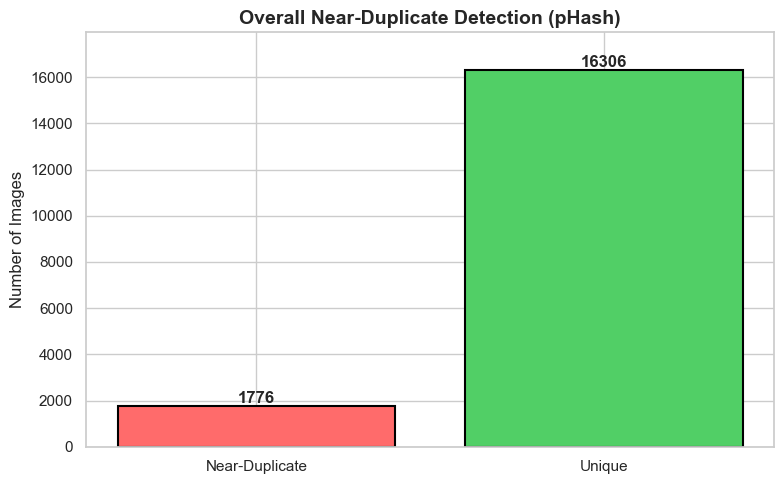

<Figure size 1400x600 with 0 Axes>

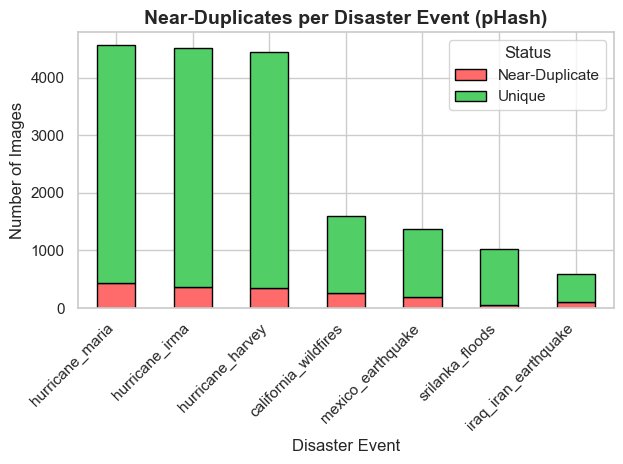

Percentage of near-duplicates per event:
               Event  Near-Duplicate %
     hurricane_maria              9.59
      hurricane_irma              8.10
    hurricane_harvey              7.98
california_wildfires             16.11
   mexico_earthquake             14.20
     srilanka_floods              5.87
iraq_iran_earthquake             18.09


In [21]:
# Visualize near-duplicates overall
plt.figure(figsize=(8, 5))

near_dup_counts = [len(near_dup_indices), len(master_df) - len(near_dup_indices)]
labels = ['Near-Duplicate', 'Unique']
colors = ['#ff6b6b', '#51cf66']

bars = plt.bar(labels, near_dup_counts, color=colors, edgecolor='black', linewidth=1.5)

for bar in bars:
    height = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2., height,
             f'{int(height)}',
             ha='center', va='bottom', fontweight='bold')

plt.title('Overall Near-Duplicate Detection (pHash)', fontsize=14, fontweight='bold')
plt.ylabel('Number of Images')
plt.ylim(0, max(near_dup_counts) * 1.1)

plt.tight_layout()
plt.show()


# Visualize near-duplicates per event
plt.figure(figsize=(14, 6))

near_dup_by_event_full = master_df.groupby('disaster_type')['has_phash_duplicate'].apply(lambda x: (x.sum(), len(x) - x.sum())).apply(pd.Series)
near_dup_by_event_full.columns = ['Near-Duplicate', 'Unique']
near_dup_by_event_full = near_dup_by_event_full.reindex(master_df['disaster_type'].value_counts().index)

near_dup_by_event_full.plot(kind='bar', stacked=True, color=['#ff6b6b', '#51cf66'], edgecolor='black', linewidth=1)

plt.title('Near-Duplicates per Disaster Event (pHash)', fontsize=14, fontweight='bold')
plt.xlabel('Disaster Event')
plt.ylabel('Number of Images')
plt.legend(title='Status', loc='upper right')
plt.xticks(rotation=45, ha='right')

plt.tight_layout()
plt.show()

# Show percentage of near-duplicates per event
pct_summary = pd.DataFrame({
    'Event': near_dup_by_event_full.index,
    'Near-Duplicate %': (near_dup_by_event_full['Near-Duplicate'] / (near_dup_by_event_full['Near-Duplicate'] + near_dup_by_event_full['Unique']) * 100).round(2)
})

print("Percentage of near-duplicates per event:")
print(pct_summary.to_string(index=False))


In [22]:
# Create train/validation/test splits and detect leakage
from sklearn.model_selection import train_test_split
import numpy as np

# Create splits (70% train, 15% val, 15% test) stratified by disaster type
train_df, temp_df = train_test_split(
    master_df, 
    test_size=0.30, 
    random_state=42, 
    stratify=master_df['disaster_type']
)

val_df, test_df = train_test_split(
    temp_df, 
    test_size=0.50, 
    random_state=42, 
    stratify=temp_df['disaster_type']
)

train_df = train_df.copy()
val_df = val_df.copy()
test_df = test_df.copy()

train_df['split'] = 'train'
val_df['split'] = 'validation'
test_df['split'] = 'test'

# Reconstruct master_df with split information
master_df = pd.concat([train_df, val_df, test_df], ignore_index=False)
master_df = master_df.sort_index()

print(f"Dataset Split Summary:")
print(f"Train set: {len(train_df)} images ({len(train_df)/len(master_df)*100:.1f}%)")
print(f"Validation set: {len(val_df)} images ({len(val_df)/len(master_df)*100:.1f}%)")
print(f"Test set: {len(test_df)} images ({len(test_df)/len(master_df)*100:.1f}%)")

# Detect duplicates across splits (using both MD5 and pHash)
leakage_md5_data = []
leakage_phash_data = []

# Check MD5 hash leakage (exact duplicates)
train_hashes_md5 = set(train_df['image_hash'].dropna())
val_hashes_md5 = set(val_df['image_hash'].dropna())
test_hashes_md5 = set(test_df['image_hash'].dropna())

train_val_md5_overlap = len(train_hashes_md5 & val_hashes_md5)
train_test_md5_overlap = len(train_hashes_md5 & test_hashes_md5)
val_test_md5_overlap = len(val_hashes_md5 & test_hashes_md5)

# Check pHash leakage (near duplicates)
train_phashes = set(train_df['perceptual_hash'].dropna())
val_phashes = set(val_df['perceptual_hash'].dropna())
test_phashes = set(test_df['perceptual_hash'].dropna())

train_val_phash_overlap = len(train_phashes & val_phashes)
train_test_phash_overlap = len(train_phashes & test_phashes)
val_test_phash_overlap = len(val_phashes & test_phashes)

print(f"\n--- MD5 Hash Overlap (Exact Duplicates) ---")
print(f"Train-Validation overlap: {train_val_md5_overlap} images")
print(f"Train-Test overlap: {train_test_md5_overlap} images")
print(f"Validation-Test overlap: {val_test_md5_overlap} images")

print(f"\n--- pHash Overlap (Near-Duplicates) ---")
print(f"Train-Validation overlap: {train_val_phash_overlap} images")
print(f"Train-Test overlap: {train_test_phash_overlap} images")
print(f"Validation-Test overlap: {val_test_phash_overlap} images")

# Find actual rows with leakage (for rows that have duplicates in other splits)
def find_leakage_rows(split_df, other_splits_hashes, hash_column):
    leakage_rows = split_df[split_df[hash_column].isin(other_splits_hashes)]
    return len(leakage_rows)

leakage_summary = {
    'Split': ['Train', 'Validation', 'Test'],
    'MD5_Leakage_to_Val': [
        find_leakage_rows(train_df, val_hashes_md5, 'image_hash'),
        find_leakage_rows(val_df, train_hashes_md5, 'image_hash'),
        0
    ],
    'MD5_Leakage_to_Test': [
        find_leakage_rows(train_df, test_hashes_md5, 'image_hash'),
        0,
        find_leakage_rows(test_df, train_hashes_md5, 'image_hash')
    ],
    'pHash_Leakage_to_Val': [
        find_leakage_rows(train_df, val_phashes, 'perceptual_hash'),
        find_leakage_rows(val_df, train_phashes, 'perceptual_hash'),
        0
    ],
    'pHash_Leakage_to_Test': [
        find_leakage_rows(train_df, test_phashes, 'perceptual_hash'),
        0,
        find_leakage_rows(test_df, train_phashes, 'perceptual_hash')
    ]
}

leakage_df = pd.DataFrame(leakage_summary)
print("\n--- Detailed Leakage Analysis ---")
print(leakage_df.to_string(index=False))


Dataset Split Summary:
Train set: 12657 images (70.0%)
Validation set: 2712 images (15.0%)
Test set: 2713 images (15.0%)

--- MD5 Hash Overlap (Exact Duplicates) ---
Train-Validation overlap: 48 images
Train-Test overlap: 51 images
Validation-Test overlap: 16 images

--- pHash Overlap (Near-Duplicates) ---
Train-Validation overlap: 128 images
Train-Test overlap: 131 images
Validation-Test overlap: 36 images

--- Detailed Leakage Analysis ---
     Split  MD5_Leakage_to_Val  MD5_Leakage_to_Test  pHash_Leakage_to_Val  pHash_Leakage_to_Test
     Train                 111                  118                   240                    234
Validation                  56                    0                   142                      0
      Test                   0                   62                     0                    147


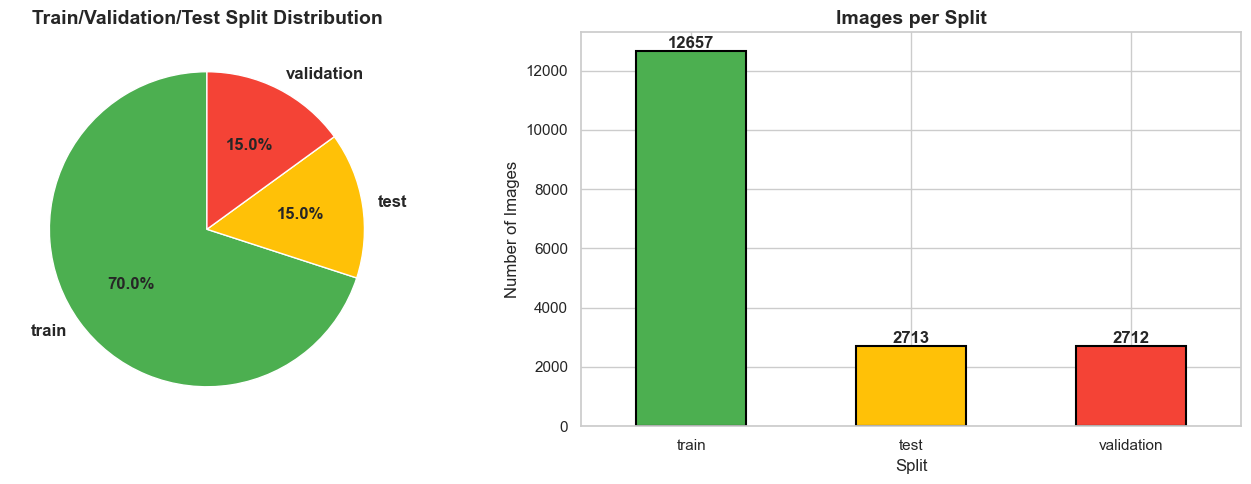

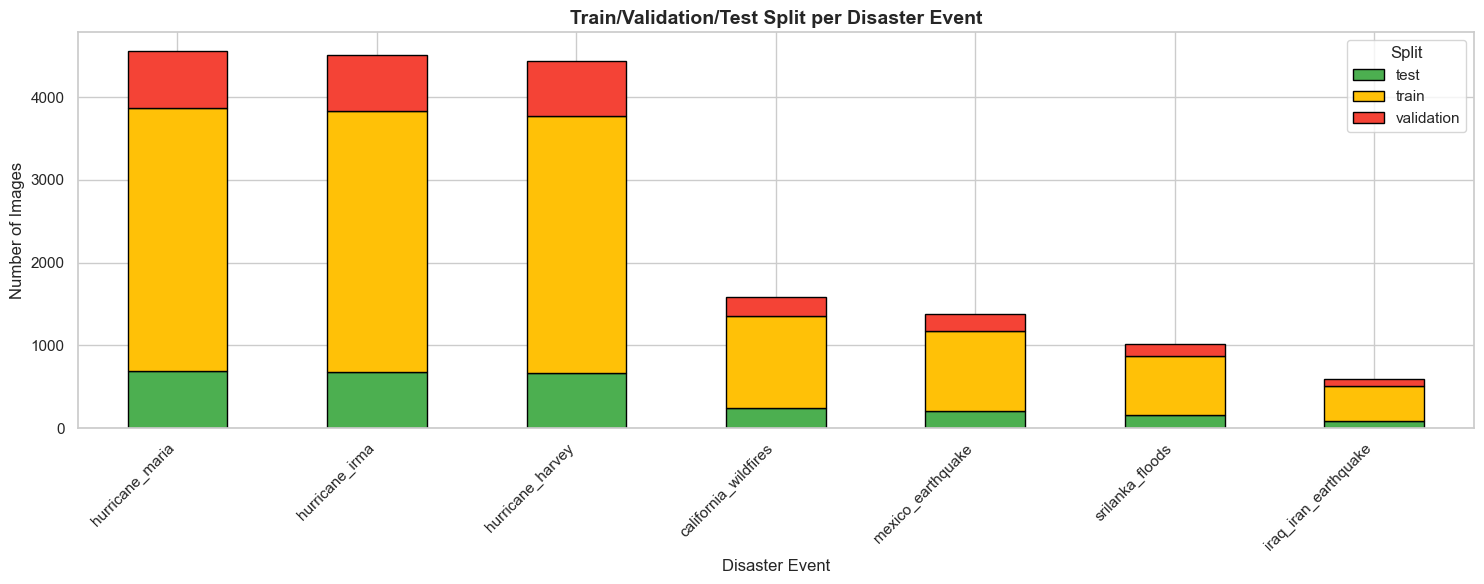

In [23]:
# Visualization: Split distribution overall
# Ensure split column exists (run cell 24 first if not present)
if 'split' not in master_df.columns:
    print("ERROR: 'split' column not found. Please run the previous cell (Create train/validation/test splits) first.")
else:
    fig, axes = plt.subplots(1, 2, figsize=(14, 5))

    # Split distribution pie chart
    split_counts = master_df['split'].value_counts()
    colors_split = ['#4CAF50', '#FFC107', '#F44336']
    axes[0].pie(split_counts.values, labels=split_counts.index, autopct='%1.1f%%', 
                colors=colors_split, startangle=90, textprops={'fontsize': 12, 'weight': 'bold'})
    axes[0].set_title('Train/Validation/Test Split Distribution', fontsize=14, fontweight='bold')

    # Split distribution by count
    split_counts.plot(kind='bar', ax=axes[1], color=colors_split, edgecolor='black', linewidth=1.5)
    for i, v in enumerate(split_counts.values):
        axes[1].text(i, v, str(v), ha='center', va='bottom', fontweight='bold')

    axes[1].set_title('Images per Split', fontsize=14, fontweight='bold')
    axes[1].set_xlabel('Split')
    axes[1].set_ylabel('Number of Images')
    axes[1].tick_params(axis='x', rotation=0)

    plt.tight_layout()
    plt.show()


    # Visualization: Split distribution by disaster event
    plt.figure(figsize=(15, 6))

    split_by_event = pd.crosstab(master_df['disaster_type'], master_df['split'])
    split_by_event = split_by_event.reindex(master_df['disaster_type'].value_counts().index)

    split_by_event.plot(kind='bar', stacked=True, ax=plt.gca(), 
                         color=['#4CAF50', '#FFC107', '#F44336'], edgecolor='black', linewidth=1)

    plt.title('Train/Validation/Test Split per Disaster Event', fontsize=14, fontweight='bold')
    plt.xlabel('Disaster Event')
    plt.ylabel('Number of Images')
    plt.legend(title='Split', loc='upper right')
    plt.xticks(rotation=45, ha='right')

    plt.tight_layout()
    plt.show()


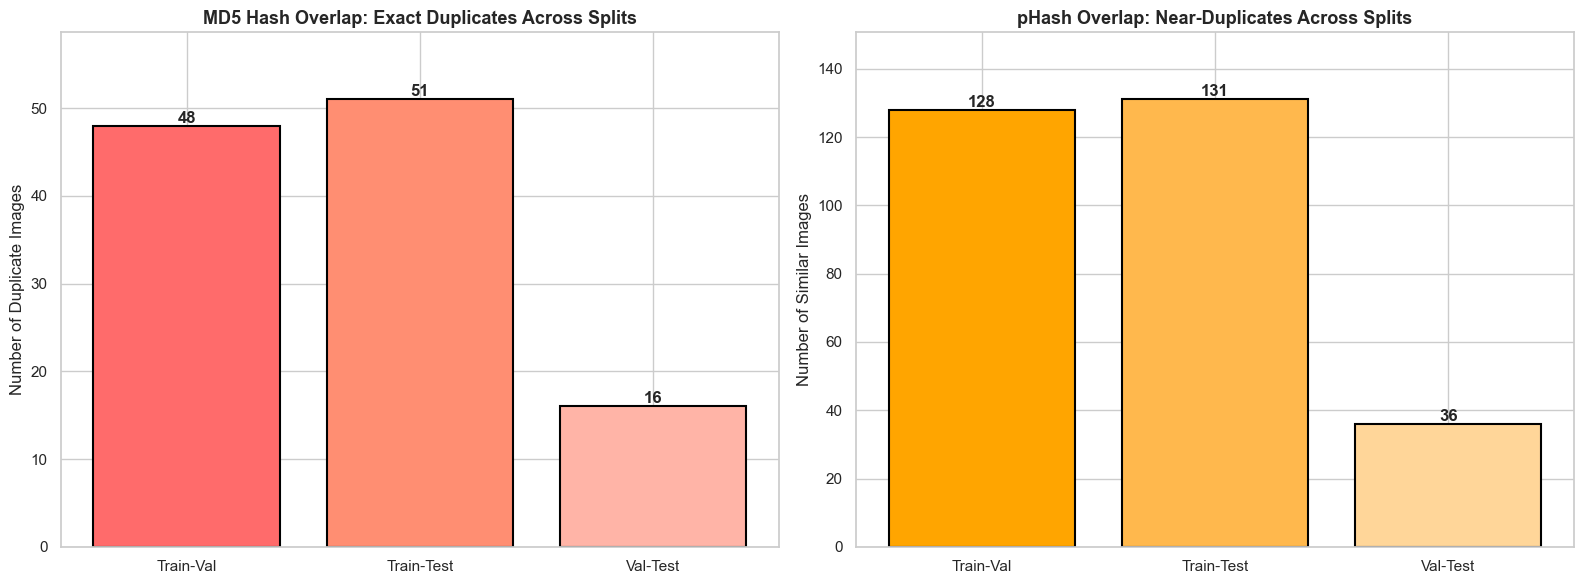


DATA LEAKAGE SUMMARY

Total images: 18082

MD5 Hash Leakage (Exact Duplicates):
  Train-Validation: 48
  Train-Test: 51
  Validation-Test: 16
  Total affected: 115

pHash Leakage (Near-Duplicates, threshold=5):
  Train-Validation: 128
  Train-Test: 131
  Validation-Test: 36
  Total affected: 295


In [24]:
# Visualization: Data leakage across splits
# Ensure split column exists (run cell 24 first if not present)
if 'split' not in master_df.columns:
    print("ERROR: 'split' column not found. Please run the previous cell (Create train/validation/test splits) first.")
else:
    fig, axes = plt.subplots(1, 2, figsize=(16, 6))

    # MD5 Hash Leakage (Exact Duplicates)
    md5_leakage = {
        'Train-Val': train_val_md5_overlap,
        'Train-Test': train_test_md5_overlap,
        'Val-Test': val_test_md5_overlap
    }

    bars1 = axes[0].bar(md5_leakage.keys(), md5_leakage.values(), 
                         color=['#FF6B6B', '#FF8E72', '#FFB4A7'], edgecolor='black', linewidth=1.5)
    axes[0].set_title('MD5 Hash Overlap: Exact Duplicates Across Splits', fontsize=13, fontweight='bold')
    axes[0].set_ylabel('Number of Duplicate Images')
    axes[0].set_ylim(0, max(md5_leakage.values()) * 1.15 if max(md5_leakage.values()) > 0 else 10)

    for bar in bars1:
        height = bar.get_height()
        if height > 0:
            axes[0].text(bar.get_x() + bar.get_width()/2., height,
                         f'{int(height)}',
                         ha='center', va='bottom', fontweight='bold')

    # pHash Leakage (Near-Duplicates)
    phash_leakage = {
        'Train-Val': train_val_phash_overlap,
        'Train-Test': train_test_phash_overlap,
        'Val-Test': val_test_phash_overlap
    }

    bars2 = axes[1].bar(phash_leakage.keys(), phash_leakage.values(), 
                         color=['#FFA500', '#FFB84D', '#FFD699'], edgecolor='black', linewidth=1.5)
    axes[1].set_title('pHash Overlap: Near-Duplicates Across Splits', fontsize=13, fontweight='bold')
    axes[1].set_ylabel('Number of Similar Images')
    axes[1].set_ylim(0, max(phash_leakage.values()) * 1.15 if max(phash_leakage.values()) > 0 else 10)

    for bar in bars2:
        height = bar.get_height()
        if height > 0:
            axes[1].text(bar.get_x() + bar.get_width()/2., height,
                         f'{int(height)}',
                         ha='center', va='bottom', fontweight='bold')

    plt.tight_layout()
    plt.show()


    # Summary statistics
    print("\n" + "="*60)
    print("DATA LEAKAGE SUMMARY")
    print("="*60)
    print(f"\nTotal images: {len(master_df)}")
    print(f"\nMD5 Hash Leakage (Exact Duplicates):")
    print(f"  Train-Validation: {train_val_md5_overlap}")
    print(f"  Train-Test: {train_test_md5_overlap}")
    print(f"  Validation-Test: {val_test_md5_overlap}")
    print(f"  Total affected: {train_val_md5_overlap + train_test_md5_overlap + val_test_md5_overlap}")

    print(f"\npHash Leakage (Near-Duplicates, threshold=5):")
    print(f"  Train-Validation: {train_val_phash_overlap}")
    print(f"  Train-Test: {train_test_phash_overlap}")
    print(f"  Validation-Test: {val_test_phash_overlap}")
    print(f"  Total affected: {train_val_phash_overlap + train_test_phash_overlap + val_test_phash_overlap}")
    print("="*60)


## Part 1: Compare pHash Among Clusters (Informativeness & Humanitarian Categories)

In [25]:
# Function to find similar images within a group using pHash
def find_similar_within_group(df_group, threshold=5):
    """
    Find similar images within a specific group based on pHash
    Returns count of similar image pairs
    """
    phashes = df_group['perceptual_hash'].dropna().tolist()
    similar_pairs = []
    
    for i in range(len(phashes)):
        for j in range(i + 1, len(phashes)):
            dist = hamming_distance(phashes[i], phashes[j])
            if dist <= threshold:
                similar_pairs.append((i, j, dist))
    
    return len(similar_pairs), similar_pairs

# Analyze pHash similarity across Image Informativeness categories
print("="*70)
print("1. PHASH SIMILARITY ANALYSIS: IMAGE INFORMATIVENESS CATEGORIES")
print("="*70)

image_info_categories = master_df['image_info'].unique()
image_info_results = {}

for category in image_info_categories:
    cat_df = master_df[master_df['image_info'] == category]
    total_images = len(cat_df)
    valid_phashes = cat_df['perceptual_hash'].notna().sum()
    
    # Find similar images within this category
    num_similar, pairs = find_similar_within_group(cat_df, threshold=5)
    
    image_info_results[category] = {
        'total_images': total_images,
        'valid_phashes': valid_phashes,
        'similar_pairs': num_similar,
        'percentage': (num_similar / valid_phashes * 100) if valid_phashes > 0 else 0
    }
    
    print(f"\nCategory: {category}")
    print(f"  Total images: {total_images}")
    print(f"  Valid pHashes: {valid_phashes}")
    print(f"  Similar image pairs (threshold=5): {num_similar}")
    print(f"  Similarity rate: {image_info_results[category]['percentage']:.2f}%")

# Analyze pHash similarity across Image Human-labeled categories
print("\n" + "="*70)
print("2. PHASH SIMILARITY ANALYSIS: IMAGE HUMAN-LABELED CATEGORIES")
print("="*70)

image_human_categories = master_df['image_human'].unique()
image_human_results = {}

for category in image_human_categories:
    cat_df = master_df[master_df['image_human'] == category]
    total_images = len(cat_df)
    valid_phashes = cat_df['perceptual_hash'].notna().sum()
    
    # Find similar images within this category
    num_similar, pairs = find_similar_within_group(cat_df, threshold=5)
    
    image_human_results[category] = {
        'total_images': total_images,
        'valid_phashes': valid_phashes,
        'similar_pairs': num_similar,
        'percentage': (num_similar / valid_phashes * 100) if valid_phashes > 0 else 0
    }
    
    print(f"\nCategory: {category}")
    print(f"  Total images: {total_images}")
    print(f"  Valid pHashes: {valid_phashes}")
    print(f"  Similar image pairs (threshold=5): {num_similar}")
    print(f"  Similarity rate: {image_human_results[category]['percentage']:.2f}%")

# Analyze pHash similarity across Text Informativeness categories
print("\n" + "="*70)
print("3. PHASH SIMILARITY ANALYSIS: TEXT INFORMATIVENESS CATEGORIES")
print("="*70)

text_info_categories = master_df['text_info'].unique()
text_info_results = {}

for category in text_info_categories:
    cat_df = master_df[master_df['text_info'] == category]
    total_images = len(cat_df)
    valid_phashes = cat_df['perceptual_hash'].notna().sum()
    
    # Find similar images within this category
    num_similar, pairs = find_similar_within_group(cat_df, threshold=5)
    
    text_info_results[category] = {
        'total_images': total_images,
        'valid_phashes': valid_phashes,
        'similar_pairs': num_similar,
        'percentage': (num_similar / valid_phashes * 100) if valid_phashes > 0 else 0
    }
    
    print(f"\nCategory: {category}")
    print(f"  Total images: {total_images}")
    print(f"  Valid pHashes: {valid_phashes}")
    print(f"  Similar image pairs (threshold=5): {num_similar}")
    print(f"  Similarity rate: {text_info_results[category]['percentage']:.2f}%")

1. PHASH SIMILARITY ANALYSIS: IMAGE INFORMATIVENESS CATEGORIES

Category: informative
  Total images: 9374
  Valid pHashes: 9374
  Similar image pairs (threshold=5): 1229
  Similarity rate: 13.11%

Category: not_informative
  Total images: 8708
  Valid pHashes: 8708
  Similar image pairs (threshold=5): 1553
  Similarity rate: 17.83%

2. PHASH SIMILARITY ANALYSIS: IMAGE HUMAN-LABELED CATEGORIES

Category: other_relevant_information
  Total images: 2529
  Valid pHashes: 2529
  Similar image pairs (threshold=5): 536
  Similarity rate: 21.19%

Category: affected_individuals
  Total images: 562
  Valid pHashes: 562
  Similar image pairs (threshold=5): 27
  Similarity rate: 4.80%

Category: infrastructure_and_utility_damage
  Total images: 3624
  Valid pHashes: 3624
  Similar image pairs (threshold=5): 351
  Similarity rate: 9.69%

Category: not_humanitarian
  Total images: 8708
  Valid pHashes: 8708
  Similar image pairs (threshold=5): 1553
  Similarity rate: 17.83%

Category: vehicle_damag

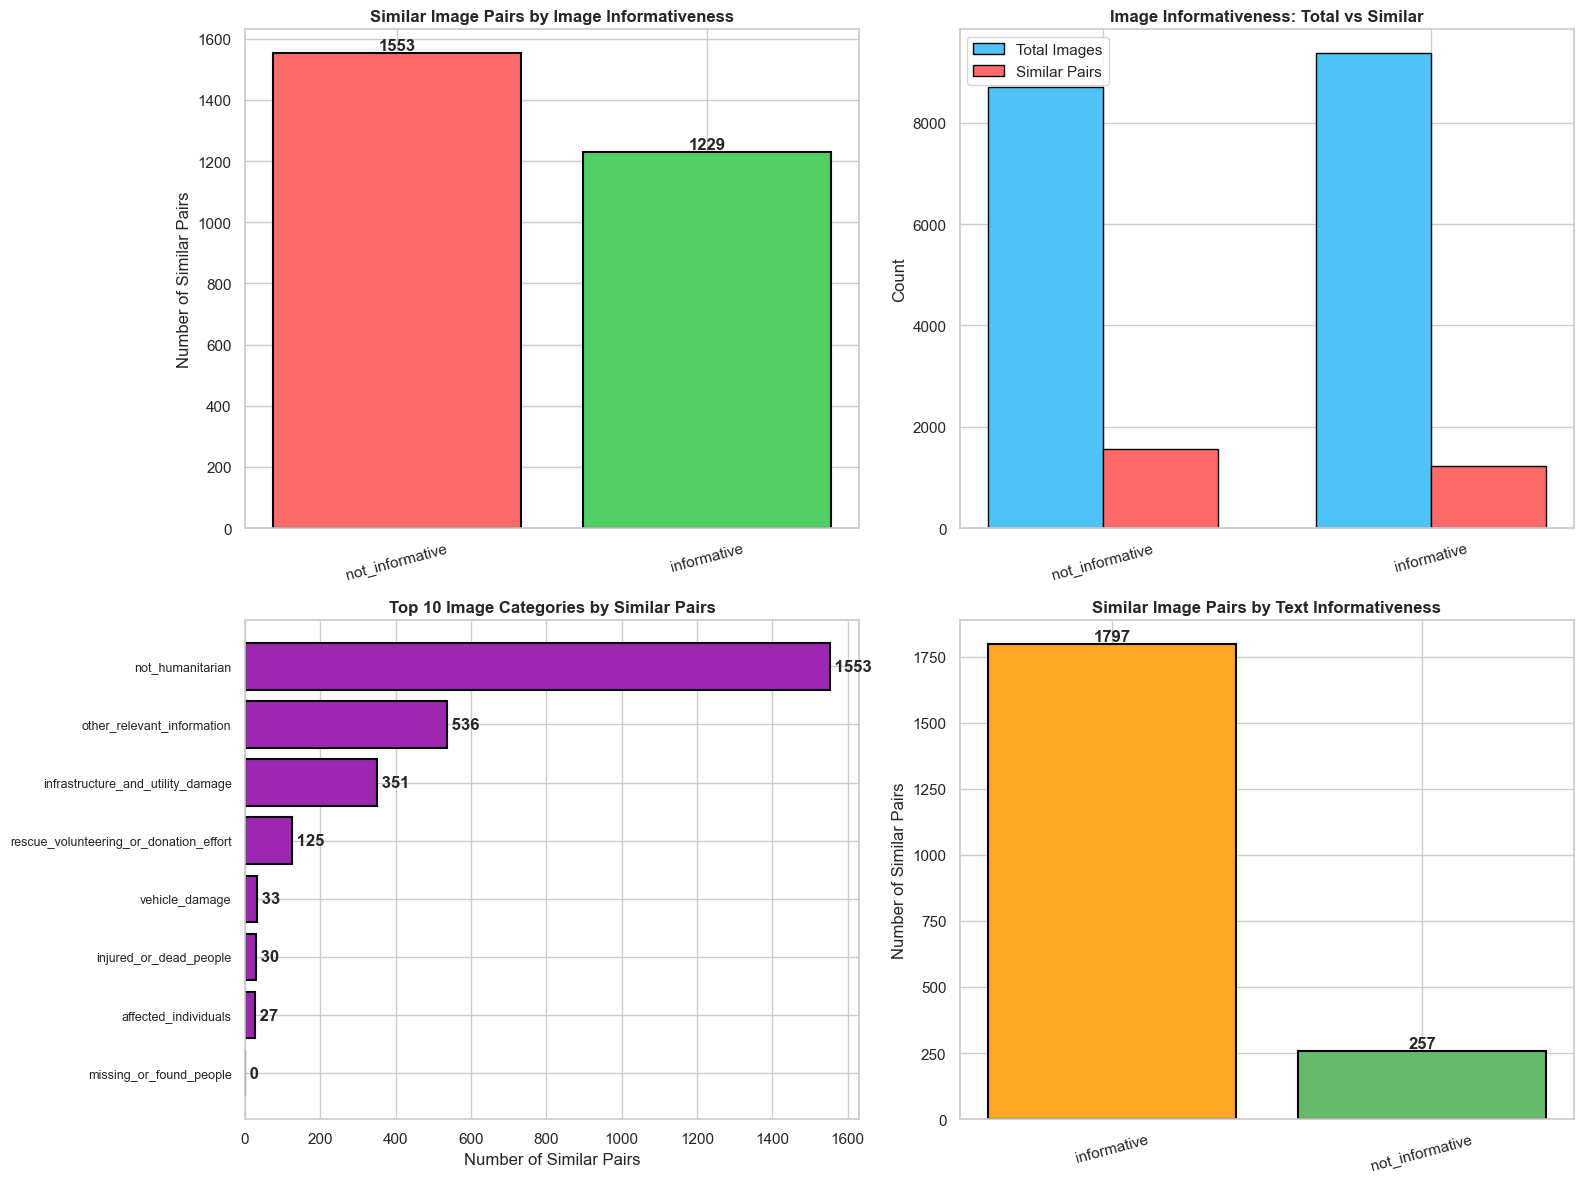


SUMMARY: INFORMATIVENESS COMPARISON
              Category Type  Total Images  Similar Pairs  Similarity Rate %
    Image Info: informative          9374           1229          13.110732
Image Info: not_informative          8708           1553          17.834175
     Text Info: informative         12855           1797          13.978996
 Text Info: not_informative          5227            257           4.916778


In [26]:
# Visualize pHash similarity across different clusters
fig, axes = plt.subplots(2, 2, figsize=(16, 12))

# 1. Image Informativeness Categories - Similar Pairs
info_df = pd.DataFrame(image_info_results).T
info_df = info_df.sort_values('similar_pairs', ascending=False)

axes[0, 0].bar(range(len(info_df)), info_df['similar_pairs'], 
               color=['#FF6B6B', '#51CF66'], edgecolor='black', linewidth=1.5)
axes[0, 0].set_xticks(range(len(info_df)))
axes[0, 0].set_xticklabels(info_df.index, rotation=15)
axes[0, 0].set_title('Similar Image Pairs by Image Informativeness', fontsize=12, fontweight='bold')
axes[0, 0].set_ylabel('Number of Similar Pairs')

for i, v in enumerate(info_df['similar_pairs']):
    axes[0, 0].text(i, v, str(int(v)), ha='center', va='bottom', fontweight='bold')

# 2. Image Informativeness - Total Images vs Similar Pairs
x = range(len(info_df))
width = 0.35

bars1 = axes[0, 1].bar([i - width/2 for i in x], info_df['total_images'], 
                        width, label='Total Images', color='#4FC3F7', edgecolor='black')
bars2 = axes[0, 1].bar([i + width/2 for i in x], info_df['similar_pairs'], 
                        width, label='Similar Pairs', color='#FF6B6B', edgecolor='black')

axes[0, 1].set_xticks(x)
axes[0, 1].set_xticklabels(info_df.index, rotation=15)
axes[0, 1].set_title('Image Informativeness: Total vs Similar', fontsize=12, fontweight='bold')
axes[0, 1].set_ylabel('Count')
axes[0, 1].legend()

# 3. Top Image Human Categories - Similar Pairs
human_df = pd.DataFrame(image_human_results).T
human_df = human_df.sort_values('similar_pairs', ascending=False).head(10)

axes[1, 0].barh(range(len(human_df)), human_df['similar_pairs'], 
                color='#9C27B0', edgecolor='black', linewidth=1.5)
axes[1, 0].set_yticks(range(len(human_df)))
axes[1, 0].set_yticklabels(human_df.index, fontsize=9)
axes[1, 0].set_title('Top 10 Image Categories by Similar Pairs', fontsize=12, fontweight='bold')
axes[1, 0].set_xlabel('Number of Similar Pairs')
axes[1, 0].invert_yaxis()

for i, v in enumerate(human_df['similar_pairs']):
    axes[1, 0].text(v, i, f' {int(v)}', va='center', fontweight='bold')

# 4. Text Informativeness Categories - Similar Pairs
text_df = pd.DataFrame(text_info_results).T
text_df = text_df.sort_values('similar_pairs', ascending=False)

axes[1, 1].bar(range(len(text_df)), text_df['similar_pairs'], 
               color=['#FFA726', '#66BB6A'], edgecolor='black', linewidth=1.5)
axes[1, 1].set_xticks(range(len(text_df)))
axes[1, 1].set_xticklabels(text_df.index, rotation=15)
axes[1, 1].set_title('Similar Image Pairs by Text Informativeness', fontsize=12, fontweight='bold')
axes[1, 1].set_ylabel('Number of Similar Pairs')

for i, v in enumerate(text_df['similar_pairs']):
    axes[1, 1].text(i, v, str(int(v)), ha='center', va='bottom', fontweight='bold')

plt.tight_layout()
plt.show()

# Summary comparison table
print("\n" + "="*80)
print("SUMMARY: INFORMATIVENESS COMPARISON")
print("="*80)

comparison_df = pd.DataFrame({
    'Category Type': ['Image Info: informative', 'Image Info: not_informative', 
                      'Text Info: informative', 'Text Info: not_informative'],
    'Total Images': [
        image_info_results.get('informative', {}).get('total_images', 0),
        image_info_results.get('not_informative', {}).get('total_images', 0),
        text_info_results.get('informative', {}).get('total_images', 0),
        text_info_results.get('not_informative', {}).get('total_images', 0)
    ],
    'Similar Pairs': [
        image_info_results.get('informative', {}).get('similar_pairs', 0),
        image_info_results.get('not_informative', {}).get('similar_pairs', 0),
        text_info_results.get('informative', {}).get('similar_pairs', 0),
        text_info_results.get('not_informative', {}).get('similar_pairs', 0)
    ],
    'Similarity Rate %': [
        image_info_results.get('informative', {}).get('percentage', 0),
        image_info_results.get('not_informative', {}).get('percentage', 0),
        text_info_results.get('informative', {}).get('percentage', 0),
        text_info_results.get('not_informative', {}).get('percentage', 0)
    ]
})

print(comparison_df.to_string(index=False))
print("="*80)

## Part 2: Duplicates Within Train, Test, and Validation Datasets

In [27]:
# Analyze duplicates WITHIN each dataset split
print("="*70)
print("DUPLICATE ANALYSIS WITHIN EACH DATASET SPLIT")
print("="*70)

def analyze_duplicates_in_split(split_df, split_name):
    """
    Analyze duplicates within a specific dataset split
    """
    print(f"\n{'='*70}")
    print(f"{split_name.upper()} SET DUPLICATE ANALYSIS")
    print(f"{'='*70}")
    
    total_images = len(split_df)
    
    # MD5 Hash duplicates (exact duplicates)
    md5_counts = split_df['image_hash'].value_counts()
    md5_duplicates = md5_counts[md5_counts > 1]
    num_duplicate_md5_hashes = len(md5_duplicates)
    total_duplicate_md5_rows = split_df['image_hash'].isin(md5_duplicates.index).sum()
    
    # pHash duplicates (near-duplicates)
    phash_counts = split_df['perceptual_hash'].value_counts()
    phash_duplicates = phash_counts[phash_counts > 1]
    num_duplicate_phash_hashes = len(phash_duplicates)
    total_duplicate_phash_rows = split_df['perceptual_hash'].isin(phash_duplicates.index).sum()
    
    print(f"\nTotal images in {split_name}: {total_images}")
    
    print(f"\n--- MD5 Hash (Exact Duplicates) ---")
    print(f"  Unique images with duplicates: {num_duplicate_md5_hashes}")
    print(f"  Total duplicate rows: {total_duplicate_md5_rows}")
    print(f"  Percentage of duplicates: {(total_duplicate_md5_rows / total_images * 100):.2f}%")
    
    print(f"\n--- pHash (Near-Duplicates, threshold=0) ---")
    print(f"  Unique pHashes with duplicates: {num_duplicate_phash_hashes}")
    print(f"  Total duplicate rows: {total_duplicate_phash_rows}")
    print(f"  Percentage of duplicates: {(total_duplicate_phash_rows / total_images * 100):.2f}%")
    
    # Show some examples
    if num_duplicate_md5_hashes > 0:
        print(f"\n--- Top 5 Most Duplicated Images (MD5) ---")
        top_5 = md5_duplicates.head(5)
        for hash_val, count in top_5.items():
            examples = split_df[split_df['image_hash'] == hash_val]
            events = examples['disaster_type'].unique()
            print(f"  Hash: {hash_val[:16]}... | Count: {count} | Events: {', '.join(events)}")
    
    return {
        'split_name': split_name,
        'total_images': total_images,
        'md5_duplicate_hashes': num_duplicate_md5_hashes,
        'md5_duplicate_rows': total_duplicate_md5_rows,
        'md5_duplicate_pct': (total_duplicate_md5_rows / total_images * 100),
        'phash_duplicate_hashes': num_duplicate_phash_hashes,
        'phash_duplicate_rows': total_duplicate_phash_rows,
        'phash_duplicate_pct': (total_duplicate_phash_rows / total_images * 100)
    }

# Analyze each split
train_dup_stats = analyze_duplicates_in_split(train_df, "Train")
val_dup_stats = analyze_duplicates_in_split(val_df, "Validation")
test_dup_stats = analyze_duplicates_in_split(test_df, "Test")

# Create summary dataframe
split_duplicates_summary = pd.DataFrame([train_dup_stats, val_dup_stats, test_dup_stats])

print("\n" + "="*70)
print("SUMMARY: DUPLICATES WITHIN EACH SPLIT")
print("="*70)
print(split_duplicates_summary.to_string(index=False))

DUPLICATE ANALYSIS WITHIN EACH DATASET SPLIT

TRAIN SET DUPLICATE ANALYSIS

Total images in Train: 12657

--- MD5 Hash (Exact Duplicates) ---
  Unique images with duplicates: 97
  Total duplicate rows: 269
  Percentage of duplicates: 2.13%

--- pHash (Near-Duplicates, threshold=0) ---
  Unique pHashes with duplicates: 277
  Total duplicate rows: 682
  Percentage of duplicates: 5.39%

--- Top 5 Most Duplicated Images (MD5) ---
  Hash: 047dfd1d3e2993fe... | Count: 27 | Events: hurricane_harvey, california_wildfires, hurricane_maria, hurricane_irma, iraq_iran_earthquake, mexico_earthquake
  Hash: f9acb31f449cb485... | Count: 20 | Events: hurricane_harvey, hurricane_maria, iraq_iran_earthquake
  Hash: 638baaedd73fe6f6... | Count: 6 | Events: mexico_earthquake, hurricane_irma, hurricane_maria, hurricane_harvey
  Hash: 2eb97b31556dfc22... | Count: 6 | Events: srilanka_floods
  Hash: 21f8855c606f86bb... | Count: 6 | Events: srilanka_floods, hurricane_irma, iraq_iran_earthquake, mexico_earthqu

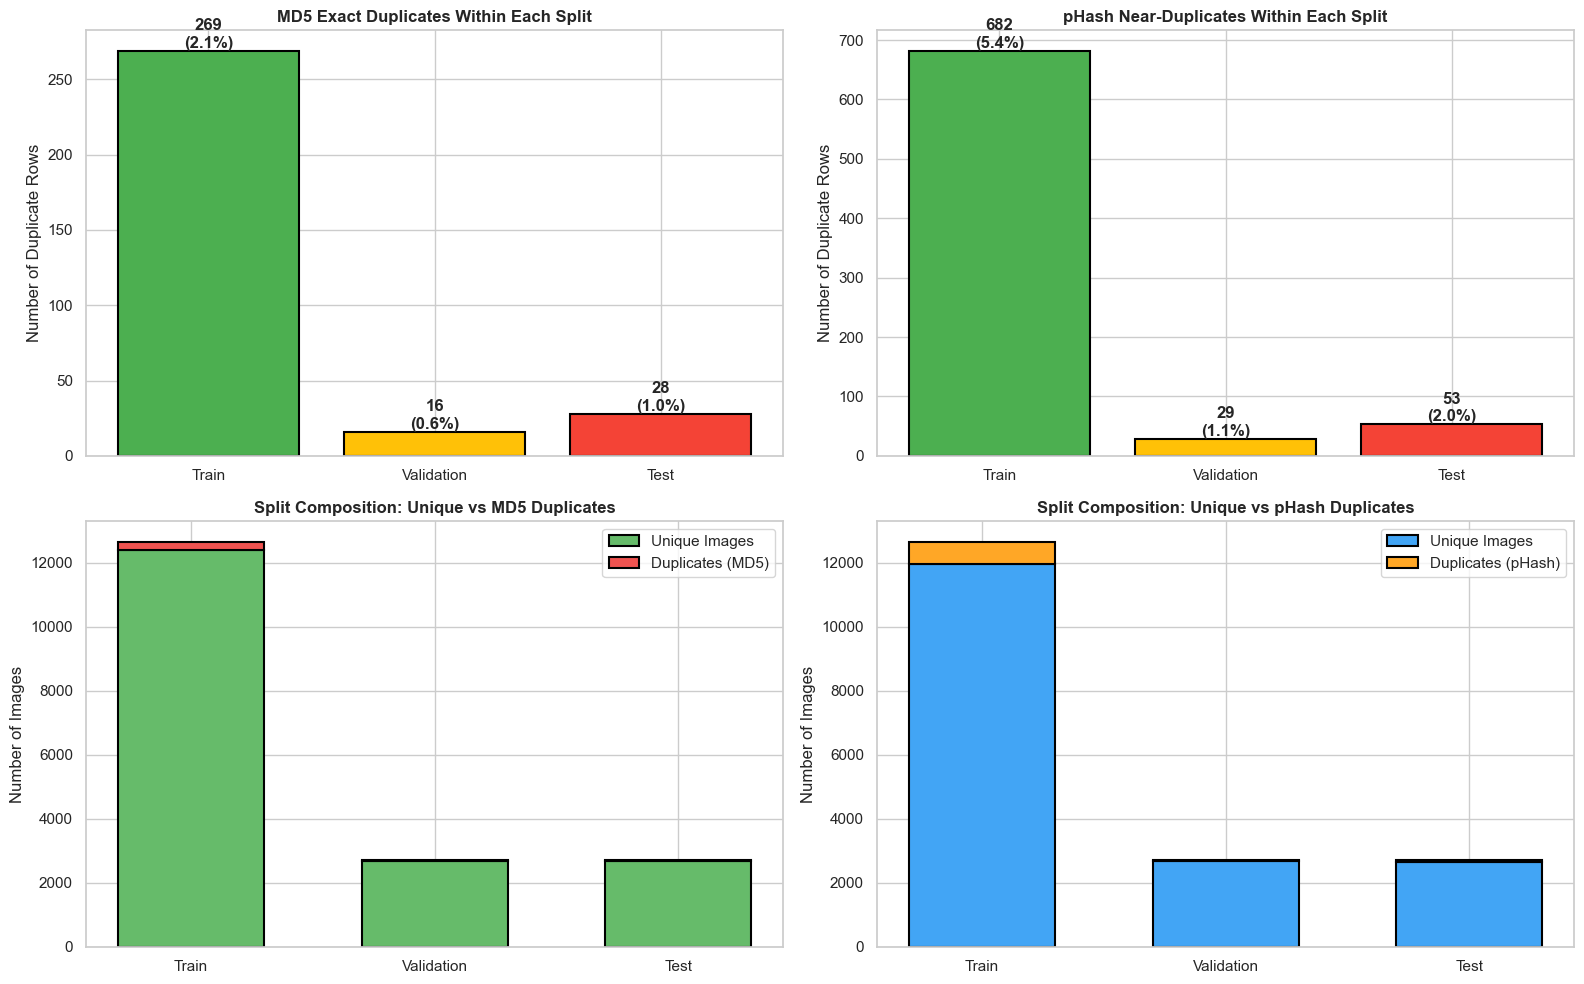

In [28]:
# Visualize duplicates within each split
fig, axes = plt.subplots(2, 2, figsize=(16, 10))

# 1. MD5 Duplicate Rows per Split
split_names = split_duplicates_summary['split_name']
md5_dup_rows = split_duplicates_summary['md5_duplicate_rows']
colors_split = ['#4CAF50', '#FFC107', '#F44336']

bars1 = axes[0, 0].bar(split_names, md5_dup_rows, color=colors_split, edgecolor='black', linewidth=1.5)
axes[0, 0].set_title('MD5 Exact Duplicates Within Each Split', fontsize=12, fontweight='bold')
axes[0, 0].set_ylabel('Number of Duplicate Rows')

for i, bar in enumerate(bars1):
    height = bar.get_height()
    axes[0, 0].text(bar.get_x() + bar.get_width()/2., height,
                    f'{int(height)}\n({split_duplicates_summary.iloc[i]["md5_duplicate_pct"]:.1f}%)',
                    ha='center', va='bottom', fontweight='bold')

# 2. pHash Duplicate Rows per Split
phash_dup_rows = split_duplicates_summary['phash_duplicate_rows']

bars2 = axes[0, 1].bar(split_names, phash_dup_rows, color=colors_split, edgecolor='black', linewidth=1.5)
axes[0, 1].set_title('pHash Near-Duplicates Within Each Split', fontsize=12, fontweight='bold')
axes[0, 1].set_ylabel('Number of Duplicate Rows')

for i, bar in enumerate(bars2):
    height = bar.get_height()
    axes[0, 1].text(bar.get_x() + bar.get_width()/2., height,
                    f'{int(height)}\n({split_duplicates_summary.iloc[i]["phash_duplicate_pct"]:.1f}%)',
                    ha='center', va='bottom', fontweight='bold')

# 3. Stacked comparison: Total vs Duplicates (MD5)
x = np.arange(len(split_names))
width = 0.6

total_images = split_duplicates_summary['total_images']
unique_images_md5 = total_images - md5_dup_rows

axes[1, 0].bar(x, unique_images_md5, width, label='Unique Images', 
               color='#66BB6A', edgecolor='black', linewidth=1.5)
axes[1, 0].bar(x, md5_dup_rows, width, bottom=unique_images_md5, label='Duplicates (MD5)', 
               color='#EF5350', edgecolor='black', linewidth=1.5)

axes[1, 0].set_xticks(x)
axes[1, 0].set_xticklabels(split_names)
axes[1, 0].set_title('Split Composition: Unique vs MD5 Duplicates', fontsize=12, fontweight='bold')
axes[1, 0].set_ylabel('Number of Images')
axes[1, 0].legend()

# 4. Stacked comparison: Total vs Duplicates (pHash)
unique_images_phash = total_images - phash_dup_rows

axes[1, 1].bar(x, unique_images_phash, width, label='Unique Images', 
               color='#42A5F5', edgecolor='black', linewidth=1.5)
axes[1, 1].bar(x, phash_dup_rows, width, bottom=unique_images_phash, label='Duplicates (pHash)', 
               color='#FFA726', edgecolor='black', linewidth=1.5)

axes[1, 1].set_xticks(x)
axes[1, 1].set_xticklabels(split_names)
axes[1, 1].set_title('Split Composition: Unique vs pHash Duplicates', fontsize=12, fontweight='bold')
axes[1, 1].set_ylabel('Number of Images')
axes[1, 1].legend()

plt.tight_layout()
plt.show()

## Part 3: Cross-Split Duplicates (Train-Test-Validation Leakage)

In [29]:
# Detailed analysis of cross-split duplicates (data leakage)
print("="*80)
print("CROSS-SPLIT DUPLICATE ANALYSIS (DATA LEAKAGE DETECTION)")
print("="*80)

def find_cross_split_duplicates(split1_df, split2_df, split1_name, split2_name, hash_column):
    """
    Find images that appear in both splits
    """
    # Get hashes from both splits
    split1_hashes = set(split1_df[hash_column].dropna())
    split2_hashes = set(split2_df[hash_column].dropna())
    
    # Find common hashes
    common_hashes = split1_hashes & split2_hashes
    
    # Get rows with common hashes from both splits
    split1_leakage = split1_df[split1_df[hash_column].isin(common_hashes)]
    split2_leakage = split2_df[split2_df[hash_column].isin(common_hashes)]
    
    return {
        'split1_name': split1_name,
        'split2_name': split2_name,
        'common_hashes': len(common_hashes),
        'split1_affected_rows': len(split1_leakage),
        'split2_affected_rows': len(split2_leakage),
        'split1_leakage': split1_leakage,
        'split2_leakage': split2_leakage,
        'common_hash_list': list(common_hashes)
    }

# Analyze MD5 hash leakage (exact duplicates)
print("\n" + "="*80)
print("MD5 HASH CROSS-SPLIT LEAKAGE (EXACT DUPLICATES)")
print("="*80)

md5_leakage_results = {}

# Train-Validation
md5_train_val = find_cross_split_duplicates(train_df, val_df, "Train", "Validation", "image_hash")
print(f"\n--- Train-Validation Leakage ---")
print(f"  Common unique images (MD5): {md5_train_val['common_hashes']}")
print(f"  Affected Train rows: {md5_train_val['split1_affected_rows']}")
print(f"  Affected Validation rows: {md5_train_val['split2_affected_rows']}")
md5_leakage_results['train_val'] = md5_train_val

# Train-Test
md5_train_test = find_cross_split_duplicates(train_df, test_df, "Train", "Test", "image_hash")
print(f"\n--- Train-Test Leakage ---")
print(f"  Common unique images (MD5): {md5_train_test['common_hashes']}")
print(f"  Affected Train rows: {md5_train_test['split1_affected_rows']}")
print(f"  Affected Test rows: {md5_train_test['split2_affected_rows']}")
md5_leakage_results['train_test'] = md5_train_test

# Validation-Test
md5_val_test = find_cross_split_duplicates(val_df, test_df, "Validation", "Test", "image_hash")
print(f"\n--- Validation-Test Leakage ---")
print(f"  Common unique images (MD5): {md5_val_test['common_hashes']}")
print(f"  Affected Validation rows: {md5_val_test['split1_affected_rows']}")
print(f"  Affected Test rows: {md5_val_test['split2_affected_rows']}")
md5_leakage_results['val_test'] = md5_val_test

# Analyze pHash leakage (near-duplicates)
print("\n" + "="*80)
print("PHASH CROSS-SPLIT LEAKAGE (NEAR-DUPLICATES)")
print("="*80)

phash_leakage_results = {}

# Train-Validation
phash_train_val = find_cross_split_duplicates(train_df, val_df, "Train", "Validation", "perceptual_hash")
print(f"\n--- Train-Validation Leakage ---")
print(f"  Common unique pHashes: {phash_train_val['common_hashes']}")
print(f"  Affected Train rows: {phash_train_val['split1_affected_rows']}")
print(f"  Affected Validation rows: {phash_train_val['split2_affected_rows']}")
phash_leakage_results['train_val'] = phash_train_val

# Train-Test
phash_train_test = find_cross_split_duplicates(train_df, test_df, "Train", "Test", "perceptual_hash")
print(f"\n--- Train-Test Leakage ---")
print(f"  Common unique pHashes: {phash_train_test['common_hashes']}")
print(f"  Affected Train rows: {phash_train_test['split1_affected_rows']}")
print(f"  Affected Test rows: {phash_train_test['split2_affected_rows']}")
phash_leakage_results['train_test'] = phash_train_test

# Validation-Test
phash_val_test = find_cross_split_duplicates(val_df, test_df, "Validation", "Test", "perceptual_hash")
print(f"\n--- Validation-Test Leakage ---")
print(f"  Common unique pHashes: {phash_val_test['common_hashes']}")
print(f"  Affected Validation rows: {phash_val_test['split1_affected_rows']}")
print(f"  Affected Test rows: {phash_val_test['split2_affected_rows']}")
phash_leakage_results['val_test'] = phash_val_test

# Create summary table
leakage_summary_table = pd.DataFrame({
    'Split Pair': ['Train-Validation', 'Train-Test', 'Validation-Test'],
    'MD5_Common_Images': [
        md5_train_val['common_hashes'],
        md5_train_test['common_hashes'],
        md5_val_test['common_hashes']
    ],
    'MD5_Total_Affected_Rows': [
        md5_train_val['split1_affected_rows'] + md5_train_val['split2_affected_rows'],
        md5_train_test['split1_affected_rows'] + md5_train_test['split2_affected_rows'],
        md5_val_test['split1_affected_rows'] + md5_val_test['split2_affected_rows']
    ],
    'pHash_Common_Images': [
        phash_train_val['common_hashes'],
        phash_train_test['common_hashes'],
        phash_val_test['common_hashes']
    ],
    'pHash_Total_Affected_Rows': [
        phash_train_val['split1_affected_rows'] + phash_train_val['split2_affected_rows'],
        phash_train_test['split1_affected_rows'] + phash_train_test['split2_affected_rows'],
        phash_val_test['split1_affected_rows'] + phash_val_test['split2_affected_rows']
    ]
})

print("\n" + "="*80)
print("SUMMARY: CROSS-SPLIT LEAKAGE")
print("="*80)
print(leakage_summary_table.to_string(index=False))
print("="*80)

CROSS-SPLIT DUPLICATE ANALYSIS (DATA LEAKAGE DETECTION)

MD5 HASH CROSS-SPLIT LEAKAGE (EXACT DUPLICATES)

--- Train-Validation Leakage ---
  Common unique images (MD5): 48
  Affected Train rows: 111
  Affected Validation rows: 56

--- Train-Test Leakage ---
  Common unique images (MD5): 51
  Affected Train rows: 118
  Affected Test rows: 62

--- Validation-Test Leakage ---
  Common unique images (MD5): 16
  Affected Validation rows: 22
  Affected Test rows: 24

PHASH CROSS-SPLIT LEAKAGE (NEAR-DUPLICATES)

--- Train-Validation Leakage ---
  Common unique pHashes: 128
  Affected Train rows: 240
  Affected Validation rows: 142

--- Train-Test Leakage ---
  Common unique pHashes: 131
  Affected Train rows: 234
  Affected Test rows: 147

--- Validation-Test Leakage ---
  Common unique pHashes: 36
  Affected Validation rows: 44
  Affected Test rows: 45

SUMMARY: CROSS-SPLIT LEAKAGE
      Split Pair  MD5_Common_Images  MD5_Total_Affected_Rows  pHash_Common_Images  pHash_Total_Affected_Rows
Tr

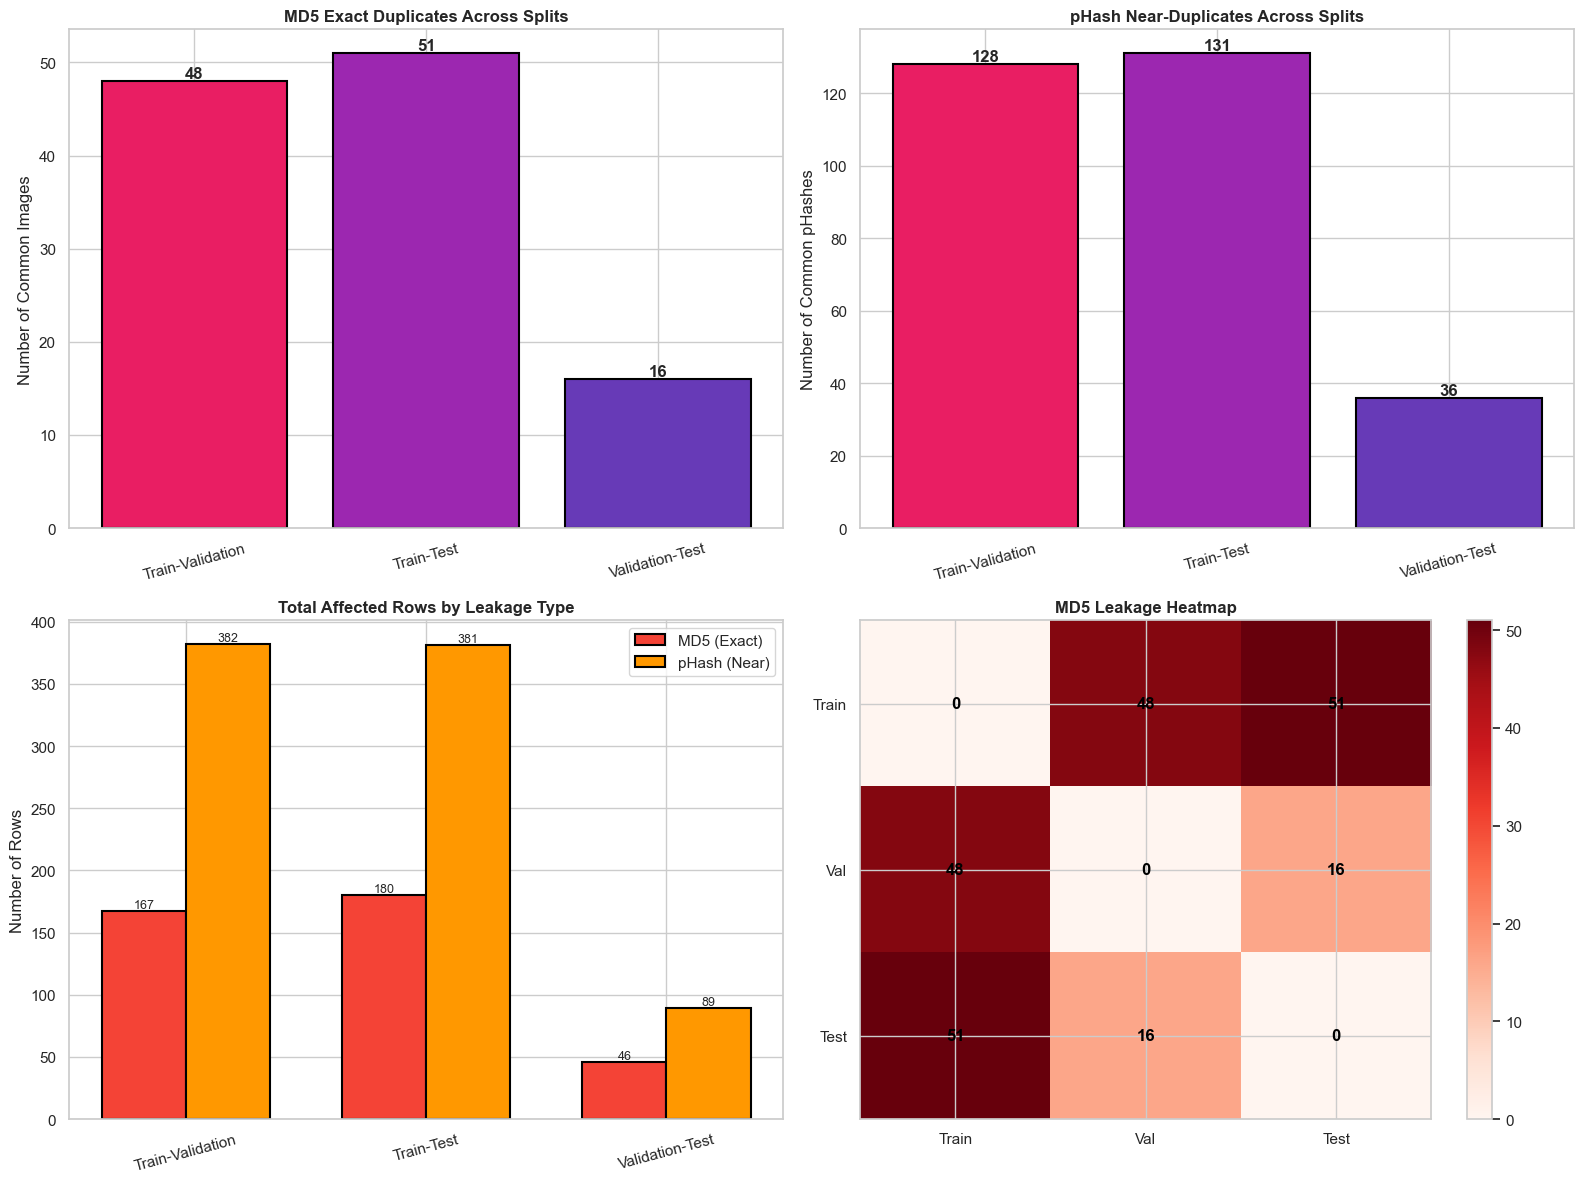



CRITICAL DATA LEAKAGE ASSESSMENT



 CRITICAL: 51 exact duplicate images found between TRAIN and TEST sets!
   This is a serious data leakage issue that will inflate model performance metrics.
   Train rows affected: 118
   Test rows affected: 62

   These similar images may cause minor data leakage.
   Train rows affected: 234
   Test rows affected: 147




In [30]:
# Visualize cross-split leakage
fig, axes = plt.subplots(2, 2, figsize=(16, 12))

# 1. MD5 Cross-Split Leakage - Common Images
split_pairs = leakage_summary_table['Split Pair']
md5_common = leakage_summary_table['MD5_Common_Images']
colors_leakage = ['#E91E63', '#9C27B0', '#673AB7']

bars1 = axes[0, 0].bar(split_pairs, md5_common, color=colors_leakage, edgecolor='black', linewidth=1.5)
axes[0, 0].set_title('MD5 Exact Duplicates Across Splits', fontsize=12, fontweight='bold')
axes[0, 0].set_ylabel('Number of Common Images')
axes[0, 0].tick_params(axis='x', rotation=15)

for bar in bars1:
    height = bar.get_height()
    axes[0, 0].text(bar.get_x() + bar.get_width()/2., height,
                    f'{int(height)}',
                    ha='center', va='bottom', fontweight='bold')

# 2. pHash Cross-Split Leakage - Common Images
phash_common = leakage_summary_table['pHash_Common_Images']

bars2 = axes[0, 1].bar(split_pairs, phash_common, color=colors_leakage, edgecolor='black', linewidth=1.5)
axes[0, 1].set_title('pHash Near-Duplicates Across Splits', fontsize=12, fontweight='bold')
axes[0, 1].set_ylabel('Number of Common pHashes')
axes[0, 1].tick_params(axis='x', rotation=15)

for bar in bars2:
    height = bar.get_height()
    axes[0, 1].text(bar.get_x() + bar.get_width()/2., height,
                    f'{int(height)}',
                    ha='center', va='bottom', fontweight='bold')

# 3. Total Affected Rows - MD5 vs pHash
x = np.arange(len(split_pairs))
width = 0.35

md5_affected = leakage_summary_table['MD5_Total_Affected_Rows']
phash_affected = leakage_summary_table['pHash_Total_Affected_Rows']

bars3 = axes[1, 0].bar(x - width/2, md5_affected, width, label='MD5 (Exact)', 
                        color='#F44336', edgecolor='black', linewidth=1.5)
bars4 = axes[1, 0].bar(x + width/2, phash_affected, width, label='pHash (Near)', 
                        color='#FF9800', edgecolor='black', linewidth=1.5)

axes[1, 0].set_xticks(x)
axes[1, 0].set_xticklabels(split_pairs, rotation=15)
axes[1, 0].set_title('Total Affected Rows by Leakage Type', fontsize=12, fontweight='bold')
axes[1, 0].set_ylabel('Number of Rows')
axes[1, 0].legend()

for bar in bars3:
    height = bar.get_height()
    if height > 0:
        axes[1, 0].text(bar.get_x() + bar.get_width()/2., height,
                        f'{int(height)}', ha='center', va='bottom', fontsize=9)

for bar in bars4:
    height = bar.get_height()
    if height > 0:
        axes[1, 0].text(bar.get_x() + bar.get_width()/2., height,
                        f'{int(height)}', ha='center', va='bottom', fontsize=9)

# 4. Leakage Heatmap
leakage_matrix_md5 = np.array([
    [0, md5_train_val['common_hashes'], md5_train_test['common_hashes']],
    [md5_train_val['common_hashes'], 0, md5_val_test['common_hashes']],
    [md5_train_test['common_hashes'], md5_val_test['common_hashes'], 0]
])

im = axes[1, 1].imshow(leakage_matrix_md5, cmap='Reds', aspect='auto')

axes[1, 1].set_xticks([0, 1, 2])
axes[1, 1].set_yticks([0, 1, 2])
axes[1, 1].set_xticklabels(['Train', 'Val', 'Test'])
axes[1, 1].set_yticklabels(['Train', 'Val', 'Test'])
axes[1, 1].set_title('MD5 Leakage Heatmap', fontsize=12, fontweight='bold')

# Add text annotations
for i in range(3):
    for j in range(3):
        text = axes[1, 1].text(j, i, int(leakage_matrix_md5[i, j]),
                               ha="center", va="center", color="black", fontweight='bold')

plt.colorbar(im, ax=axes[1, 1])
plt.tight_layout()
plt.show()

# Critical leakage warning
print("\n")
print("CRITICAL DATA LEAKAGE ASSESSMENT")
print("\n")

if md5_train_test['common_hashes'] > 0:
    print(f"\n CRITICAL: {md5_train_test['common_hashes']} exact duplicate images found between TRAIN and TEST sets!")
    print(f"   This is a serious data leakage issue that will inflate model performance metrics.")
    print(f"   Train rows affected: {md5_train_test['split1_affected_rows']}")
    print(f"   Test rows affected: {md5_train_test['split2_affected_rows']}")
else:
    print("\n GOOD: No exact duplicate images found between TRAIN and TEST sets (MD5).")

if phash_train_test['common_hashes'] > 0:
    print(f"\n  WARNING: {phash_train_test['common_hashes']} near-duplicate images found between TRAIN and TEST sets (pHash)!")
    print(f"   These similar images may cause minor data leakage.")
    print(f"   Train rows affected: {phash_train_test['split1_affected_rows']}")
    print(f"   Test rows affected: {phash_train_test['split2_affected_rows']}")
else:
    print(" GOOD: No near-duplicate images found between TRAIN and TEST sets (pHash).")

print("\n")

In [31]:
# Show specific examples of leaked images (Train-Test)
print("="*80)
print("EXAMPLES OF TRAIN-TEST LEAKAGE")
print("="*80)

# MD5 Examples (Exact Duplicates)
if md5_train_test['common_hashes'] > 0:
    print(f"\n--- MD5 EXACT DUPLICATES IN TRAIN-TEST ---")
    print(f"Showing top 10 examples:\n")
    
    example_count = 0
    for hash_val in list(md5_train_test['common_hash_list'])[:10]:
        train_row = train_df[train_df['image_hash'] == hash_val].iloc[0]
        test_row = test_df[test_df['image_hash'] == hash_val].iloc[0]
        
        print(f"Example {example_count + 1}:")
        print(f"  MD5 Hash: {hash_val[:32]}...")
        print(f"  TRAIN: Index {train_row.name} | Event: {train_row['disaster_type']} | Path: {train_row['image_path']}")
        print(f"  TEST:  Index {test_row.name} | Event: {test_row['disaster_type']} | Path: {test_row['image_path']}")
        print(f"  Image Info: {train_row['image_info']} | Human Label: {train_row['image_human']}")
        print()
        
        example_count += 1
else:
    print("\n No MD5 exact duplicates found between Train and Test sets.")

# pHash Examples (Near-Duplicates)
if phash_train_test['common_hashes'] > 0:
    print(f"\n--- PHASH NEAR-DUPLICATES IN TRAIN-TEST ---")
    print(f"Showing top 10 examples:\n")
    
    example_count = 0
    for hash_val in list(phash_train_test['common_hash_list'])[:10]:
        train_rows = train_df[train_df['perceptual_hash'] == hash_val]
        test_rows = test_df[test_df['perceptual_hash'] == hash_val]
        
        train_row = train_rows.iloc[0]
        test_row = test_rows.iloc[0]
        
        print(f"Example {example_count + 1}:")
        print(f"  pHash: {hash_val}")
        print(f"  TRAIN: {len(train_rows)} occurrence(s) | First at index {train_row.name}")
        print(f"         Event: {train_row['disaster_type']} | Path: {train_row['image_path']}")
        print(f"  TEST:  {len(test_rows)} occurrence(s) | First at index {test_row.name}")
        print(f"         Event: {test_row['disaster_type']} | Path: {test_row['image_path']}")
        print(f"  Image Info: {train_row['image_info']} | Human Label: {train_row['image_human']}")
        print()
        
        example_count += 1
else:
    print("\n No pHash near-duplicates found between Train and Test sets.")

# Analysis of leaked images by category
if md5_train_test['common_hashes'] > 0 or phash_train_test['common_hashes'] > 0:
    print("\n" + "="*80)
    print("LEAKED IMAGES BY CATEGORY (Train-Test)")
    print("="*80)
    
    # Get all leaked images
    all_leaked_train = pd.concat([
        md5_train_test['split1_leakage'],
        phash_train_test['split1_leakage']
    ]).drop_duplicates()
    
    if len(all_leaked_train) > 0:
        print(f"\n--- Leaked Images by Disaster Type ---")
        leaked_by_event = all_leaked_train['disaster_type'].value_counts()
        for event, count in leaked_by_event.items():
            print(f"  {event}: {count} images")
        
        print(f"\n--- Leaked Images by Informativeness ---")
        leaked_by_info = all_leaked_train['image_info'].value_counts()
        for info, count in leaked_by_info.items():
            print(f"  {info}: {count} images")
        
        print(f"\n--- Leaked Images by Human Label ---")
        leaked_by_human = all_leaked_train['image_human'].value_counts()
        for label, count in leaked_by_human.items():
            print(f"  {label}: {count} images")

EXAMPLES OF TRAIN-TEST LEAKAGE

--- MD5 EXACT DUPLICATES IN TRAIN-TEST ---
Showing top 10 examples:

Example 1:
  MD5 Hash: ce762e1d7e153218afe2bd1df4eef815...
  TRAIN: Index 139 | Event: california_wildfires | Path: data_image/california_wildfires/10_10_2017/917844475686162437_0.jpg
  TEST:  Index 152 | Event: california_wildfires | Path: data_image/california_wildfires/10_10_2017/917849898963349510_0.jpg
  Image Info: not_informative | Human Label: not_humanitarian

Example 2:
  MD5 Hash: 8b1d3c6fec4255cd021c22153f98ddba...
  TRAIN: Index 5374 | Event: hurricane_harvey | Path: data_image/hurricane_harvey/14_9_2017/908366018073985026_0.jpg
  TEST:  Index 4779 | Event: hurricane_harvey | Path: data_image/hurricane_harvey/11_9_2017/907335391103111168_0.jpg
  Image Info: informative | Human Label: rescue_volunteering_or_donation_effort

Example 3:
  MD5 Hash: c32f621601c9c6e71d8e77f0312fe800...
  TRAIN: Index 5335 | Event: hurricane_harvey | Path: data_image/hurricane_harvey/14_9_2017/90

## Summary: Complete pHash Analysis Report

In [32]:
# COMPREHENSIVE SUMMARY OF ALL ANALYSES
print("╔" + "═"*98 + "╗")
print("║" + " "*30 + "COMPLETE PHASH ANALYSIS SUMMARY" + " "*37 + "║")
print("╚" + "═"*98 + "╝")

print("\n" + "─"*100)
print("1. PHASH SIMILARITY WITHIN CLUSTERS")
print("─"*100)

print("\nImage Informativeness:")
for cat, data in image_info_results.items():
    print(f"  • {cat:20s}: {data['similar_pairs']:4d} similar pairs out of {data['total_images']:5d} images ({data['percentage']:5.2f}%)")

print("\nTop 5 Image Human Categories (by similar pairs):")
top_human_cats = sorted(image_human_results.items(), key=lambda x: x[1]['similar_pairs'], reverse=True)[:5]
for cat, data in top_human_cats:
    print(f"  • {cat:40s}: {data['similar_pairs']:4d} similar pairs ({data['percentage']:5.2f}%)")

print("\n" + "─"*100)
print("2. DUPLICATES WITHIN EACH DATASET SPLIT")
print("─"*100)

for split_data in [train_dup_stats, val_dup_stats, test_dup_stats]:
    print(f"\n{split_data['split_name']} Set ({split_data['total_images']} images):")
    print(f"  • MD5 Exact Duplicates:  {split_data['md5_duplicate_rows']:4d} rows ({split_data['md5_duplicate_pct']:5.2f}%)")
    print(f"  • pHash Near-Duplicates: {split_data['phash_duplicate_rows']:4d} rows ({split_data['phash_duplicate_pct']:5.2f}%)")

print("\n" + "─"*100)
print("3. CROSS-SPLIT LEAKAGE (TRAIN-TEST-VALIDATION)")
print("─"*100)

print("\nMD5 Exact Duplicate Leakage:")
print(f"  • Train ↔ Validation:  {md5_train_val['common_hashes']:3d} common images")
print(f"  • Train ↔ Test:        {md5_train_test['common_hashes']:3d} common images {'🚨 CRITICAL!' if md5_train_test['common_hashes'] > 0 else 'No common images'}")
print(f"  • Validation ↔ Test:   {md5_val_test['common_hashes']:3d} common images")

print("\npHash Near-Duplicate Leakage:")
print(f"  • Train ↔ Validation:  {phash_train_val['common_hashes']:3d} common pHashes")
print(f"  • Train ↔ Test:        {phash_train_test['common_hashes']:3d} common pHashes {'⚠️  WARNING!' if phash_train_test['common_hashes'] > 0 else 'No common hashes'}")
print(f"  • Validation ↔ Test:   {phash_val_test['common_hashes']:3d} common pHashes")

print("\n" + "─"*100)
print("KEY FINDINGS & RECOMMENDATIONS")
print("─"*100)

# Calculate key metrics
total_dataset_size = len(master_df)
informative_imgs = image_info_results.get('informative', {}).get('total_images', 0)
not_informative_imgs = image_info_results.get('not_informative', {}).get('total_images', 0)
informative_similar = image_info_results.get('informative', {}).get('similar_pairs', 0)
not_informative_similar = image_info_results.get('not_informative', {}).get('similar_pairs', 0)

print(f"\n Dataset Composition:")
print(f"   • Total images: {total_dataset_size}")
print(f"   • Informative: {informative_imgs} ({informative_imgs/total_dataset_size*100:.1f}%)")
print(f"   • Not informative: {not_informative_imgs} ({not_informative_imgs/total_dataset_size*100:.1f}%)")

print(f"\n Similarity Patterns:")
print(f"   • Informative images have {informative_similar} similar pairs")
print(f"   • Non-informative images have {not_informative_similar} similar pairs")
if informative_imgs > 0 and not_informative_imgs > 0:
    info_rate = (informative_similar / informative_imgs) * 100
    non_info_rate = (not_informative_similar / not_informative_imgs) * 100
    print(f"   • Similarity rate: Informative {info_rate:.2f}% vs Non-informative {non_info_rate:.2f}%")

print(f"\n Data Quality Issues:")
total_within_splits = train_dup_stats['md5_duplicate_rows'] + val_dup_stats['md5_duplicate_rows'] + test_dup_stats['md5_duplicate_rows']
print(f"   • {total_within_splits} duplicate rows exist WITHIN splits")

if md5_train_test['common_hashes'] > 0:
    print(f"   •  CRITICAL: {md5_train_test['common_hashes']} exact duplicates leak from Train to Test")
    print(f"     → This will artificially inflate model performance!")
    print(f"     → RECOMMENDATION: Remove duplicates from test set or retrain-test split")

if phash_train_test['common_hashes'] > 0:
    print(f"   •  {phash_train_test['common_hashes']} near-duplicates leak from Train to Test")
    print(f"     → May cause minor performance inflation")
    print(f"     → RECOMMENDATION: Consider removing or monitoring these cases")

if md5_train_test['common_hashes'] == 0 and phash_train_test['common_hashes'] == 0:
    print(f"   • No leakage detected between Train and Test sets")
    print(f"     → Dataset split is valid for model evaluation")

print("\n" + "╚" + "═"*98 + "╝")
print("\nAnalysis complete! All results are stored in the following variables:")
print("  • image_info_results, image_human_results, text_info_results")
print("  • train_dup_stats, val_dup_stats, test_dup_stats")
print("  • md5_leakage_results, phash_leakage_results")
print("  • leakage_summary_table")

╔══════════════════════════════════════════════════════════════════════════════════════════════════╗
║                              COMPLETE PHASH ANALYSIS SUMMARY                                     ║
╚══════════════════════════════════════════════════════════════════════════════════════════════════╝

────────────────────────────────────────────────────────────────────────────────────────────────────
1. PHASH SIMILARITY WITHIN CLUSTERS
────────────────────────────────────────────────────────────────────────────────────────────────────

Image Informativeness:
  • informative         : 1229 similar pairs out of  9374 images (13.11%)
  • not_informative     : 1553 similar pairs out of  8708 images (17.83%)

Top 5 Image Human Categories (by similar pairs):
  • not_humanitarian                        : 1553 similar pairs (17.83%)
  • other_relevant_information              :  536 similar pairs (21.19%)
  • infrastructure_and_utility_damage       :  351 similar pairs ( 9.69%)
  • rescue_vol

## Part 4: Task-wise Event Duplicate Data and Leakage Assessment

In [33]:
# Task-wise duplicate and leakage assessment for CrisisMMD tasks
# Uses the same hash-based strategy as earlier sections, but breaks results down by task labels.

def _require_columns(df, required_cols):
    missing = [c for c in required_cols if c not in df.columns]
    if missing:
        raise ValueError(f"Missing required columns: {missing}")


def _get_split_frames(master):
    """Return train/validation/test dataframes, reusing existing split dfs when available."""
    if all(name in globals() for name in ["train_df", "val_df", "test_df"]):
        return train_df.copy(), val_df.copy(), test_df.copy()

    if "split" not in master.columns:
        raise ValueError(
            "No split information found. Run the split cell first so train/validation/test can be analyzed."
        )

    split_map = {
        "train": master[master["split"] == "train"].copy(),
        "validation": master[master["split"] == "validation"].copy(),
        "test": master[master["split"] == "test"].copy(),
    }

    if any(len(v) == 0 for v in split_map.values()):
        raise ValueError("At least one split is empty. Please re-run split creation.")

    return split_map["train"], split_map["validation"], split_map["test"]


def _normalize_task_labels(df):
    """Normalize task labels to v2.0 naming so category filters are consistent."""
    out = df.copy()

    if "image_human" in out.columns:
        out["task2_humanitarian"] = (
            out["image_human"]
            .astype(str)
            .str.strip()
            .replace({"not_relevant_or_cant_judge": "not_humanitarian"})
        )

    if "image_damage" in out.columns:
        out["task3_damage"] = out["image_damage"].fillna("dont_know_or_cant_judge").astype(str).str.strip()

    if "image_info" in out.columns:
        out["task1_informative"] = out["image_info"].astype(str).str.strip()

    return out


def _event_duplicate_table(df, task_col, class_name):
    subset = df[df[task_col] == class_name].copy()

    if len(subset) == 0:
        return pd.DataFrame(columns=[
            "event",
            "rows_in_class",
            "md5_duplicate_rows",
            "phash_duplicate_rows",
        ])

    base = subset.groupby("disaster_type").size().rename("rows_in_class")

    md5_dup_rows = (
        subset[subset["image_hash"].duplicated(keep=False)]
        .groupby("disaster_type")
        .size()
        .rename("md5_duplicate_rows")
    )

    phash_dup_rows = (
        subset[subset["perceptual_hash"].duplicated(keep=False)]
        .groupby("disaster_type")
        .size()
        .rename("phash_duplicate_rows")
    )

    event_table = pd.concat([base, md5_dup_rows, phash_dup_rows], axis=1).fillna(0).astype(int)
    event_table = event_table.reset_index().rename(columns={"disaster_type": "event"})
    return event_table.sort_values("rows_in_class", ascending=False)


def _pair_leakage(df_a, df_b, hash_col):
    hashes_a = set(df_a[hash_col].dropna())
    hashes_b = set(df_b[hash_col].dropna())
    common = hashes_a & hashes_b

    affected_a = int(df_a[hash_col].isin(common).sum())
    affected_b = int(df_b[hash_col].isin(common).sum())

    return len(common), affected_a + affected_b


def _class_leakage_table(train, val, test, task_col, class_name):
    split_data = {
        "Train": train[train[task_col] == class_name],
        "Validation": val[val[task_col] == class_name],
        "Test": test[test[task_col] == class_name],
    }

    rows = []
    pairs = [("Train", "Validation"), ("Train", "Test"), ("Validation", "Test")]

    for a, b in pairs:
        df_a = split_data[a]
        df_b = split_data[b]

        md5_common, md5_affected = _pair_leakage(df_a, df_b, "image_hash")
        phash_common, phash_affected = _pair_leakage(df_a, df_b, "perceptual_hash")

        rows.append({
            "split_pair": f"{a}-{b}",
            "md5_common_images": md5_common,
            "md5_total_affected_rows": md5_affected,
            "phash_common_images": phash_common,
            "phash_total_affected_rows": phash_affected,
            "rows_in_pair": len(df_a) + len(df_b),
        })

    return pd.DataFrame(rows)


# Validate required data first
_require_columns(master_df, [
    "disaster_type",
    "image_hash",
    "perceptual_hash",
    "image_info",
    "image_human",
    "image_damage",
])

train_local, val_local, test_local = _get_split_frames(master_df)
master_task_df = _normalize_task_labels(master_df)
train_task_df = _normalize_task_labels(train_local)
val_task_df = _normalize_task_labels(val_local)
test_task_df = _normalize_task_labels(test_local)

TASK_DEFS = {
    "Task 1 - Informative vs Not informative": {
        "column": "task1_informative",
        "classes": ["informative", "not_informative"],
    },
    "Task 2 - Humanitarian categories": {
        "column": "task2_humanitarian",
        "classes": [
            "affected_individuals",
            "infrastructure_and_utility_damage",
            "injured_or_dead_people",
            "missing_or_found_people",
            "rescue_volunteering_or_donation_effort",
            "vehicle_damage",
            "other_relevant_information",
            "not_humanitarian",
        ],
    },
    "Task 3 - Damage severity assessment": {
        "column": "task3_damage",
        "classes": [
            "severe_damage",
            "mild_damage",
            "little_or_no_damage",
            "dont_know_or_cant_judge",
        ],
    },
}

# Store all outputs for later use
per_task_duplicate_event_tables = {}
per_task_leakage_tables = {}

print("=" * 100)
print("TASK-WISE EVENT DUPLICATE DATA + DATA LEAKAGE ASSESSMENT")
print("=" * 100)

for task_name, cfg in TASK_DEFS.items():
    col = cfg["column"]
    classes = cfg["classes"]

    per_task_duplicate_event_tables[task_name] = {}
    per_task_leakage_tables[task_name] = {}

    print("\n" + "-" * 100)
    print(task_name)
    print("-" * 100)

    available_classes = set(master_task_df[col].dropna().unique())

    for cls in classes:
        if cls not in available_classes:
            continue

        event_dup_table = _event_duplicate_table(master_task_df, col, cls)
        leakage_table = _class_leakage_table(train_task_df, val_task_df, test_task_df, col, cls)

        per_task_duplicate_event_tables[task_name][cls] = event_dup_table
        per_task_leakage_tables[task_name][cls] = leakage_table

        print(f"\nClass: {cls}")
        print(f"Rows in class: {len(master_task_df[master_task_df[col] == cls])}")

        md5_event_total = int(event_dup_table["md5_duplicate_rows"].sum()) if len(event_dup_table) else 0
        phash_event_total = int(event_dup_table["phash_duplicate_rows"].sum()) if len(event_dup_table) else 0

        print(f"  Event duplicate rows (MD5 total): {md5_event_total}")
        print(f"  Event duplicate rows (pHash total): {phash_event_total}")

        md5_train_test = int(
            leakage_table.loc[leakage_table["split_pair"] == "Train-Test", "md5_common_images"].iloc[0]
        )
        phash_train_test = int(
            leakage_table.loc[leakage_table["split_pair"] == "Train-Test", "phash_common_images"].iloc[0]
        )

        print(f"  Train-Test leakage (MD5 common images): {md5_train_test}")
        print(f"  Train-Test leakage (pHash common images): {phash_train_test}")

# print("\n" + "=" * 100)
# print("Saved outputs:")
# print("  - per_task_duplicate_event_tables[task_name][class_name]")
# print("  - per_task_leakage_tables[task_name][class_name]")
# print("\nExample usage:")
# print("  per_task_duplicate_event_tables['Task 2 - Humanitarian categories']['vehicle_damage'].head()")
# print("  per_task_leakage_tables['Task 1 - Informative vs Not informative']['informative']")
# print("=" * 100)

TASK-WISE EVENT DUPLICATE DATA + DATA LEAKAGE ASSESSMENT

----------------------------------------------------------------------------------------------------
Task 1 - Informative vs Not informative
----------------------------------------------------------------------------------------------------

Class: informative
Rows in class: 9374
  Event duplicate rows (MD5 total): 219
  Event duplicate rows (pHash total): 780
  Train-Test leakage (MD5 common images): 22
  Train-Test leakage (pHash common images): 86

Class: not_informative
Rows in class: 8708
  Event duplicate rows (MD5 total): 241
  Event duplicate rows (pHash total): 369
  Train-Test leakage (MD5 common images): 23
  Train-Test leakage (pHash common images): 31

----------------------------------------------------------------------------------------------------
Task 2 - Humanitarian categories
----------------------------------------------------------------------------------------------------

Class: affected_individuals
Row

## Part 4 Visualizations: Task-wise Duplicates and Leakage

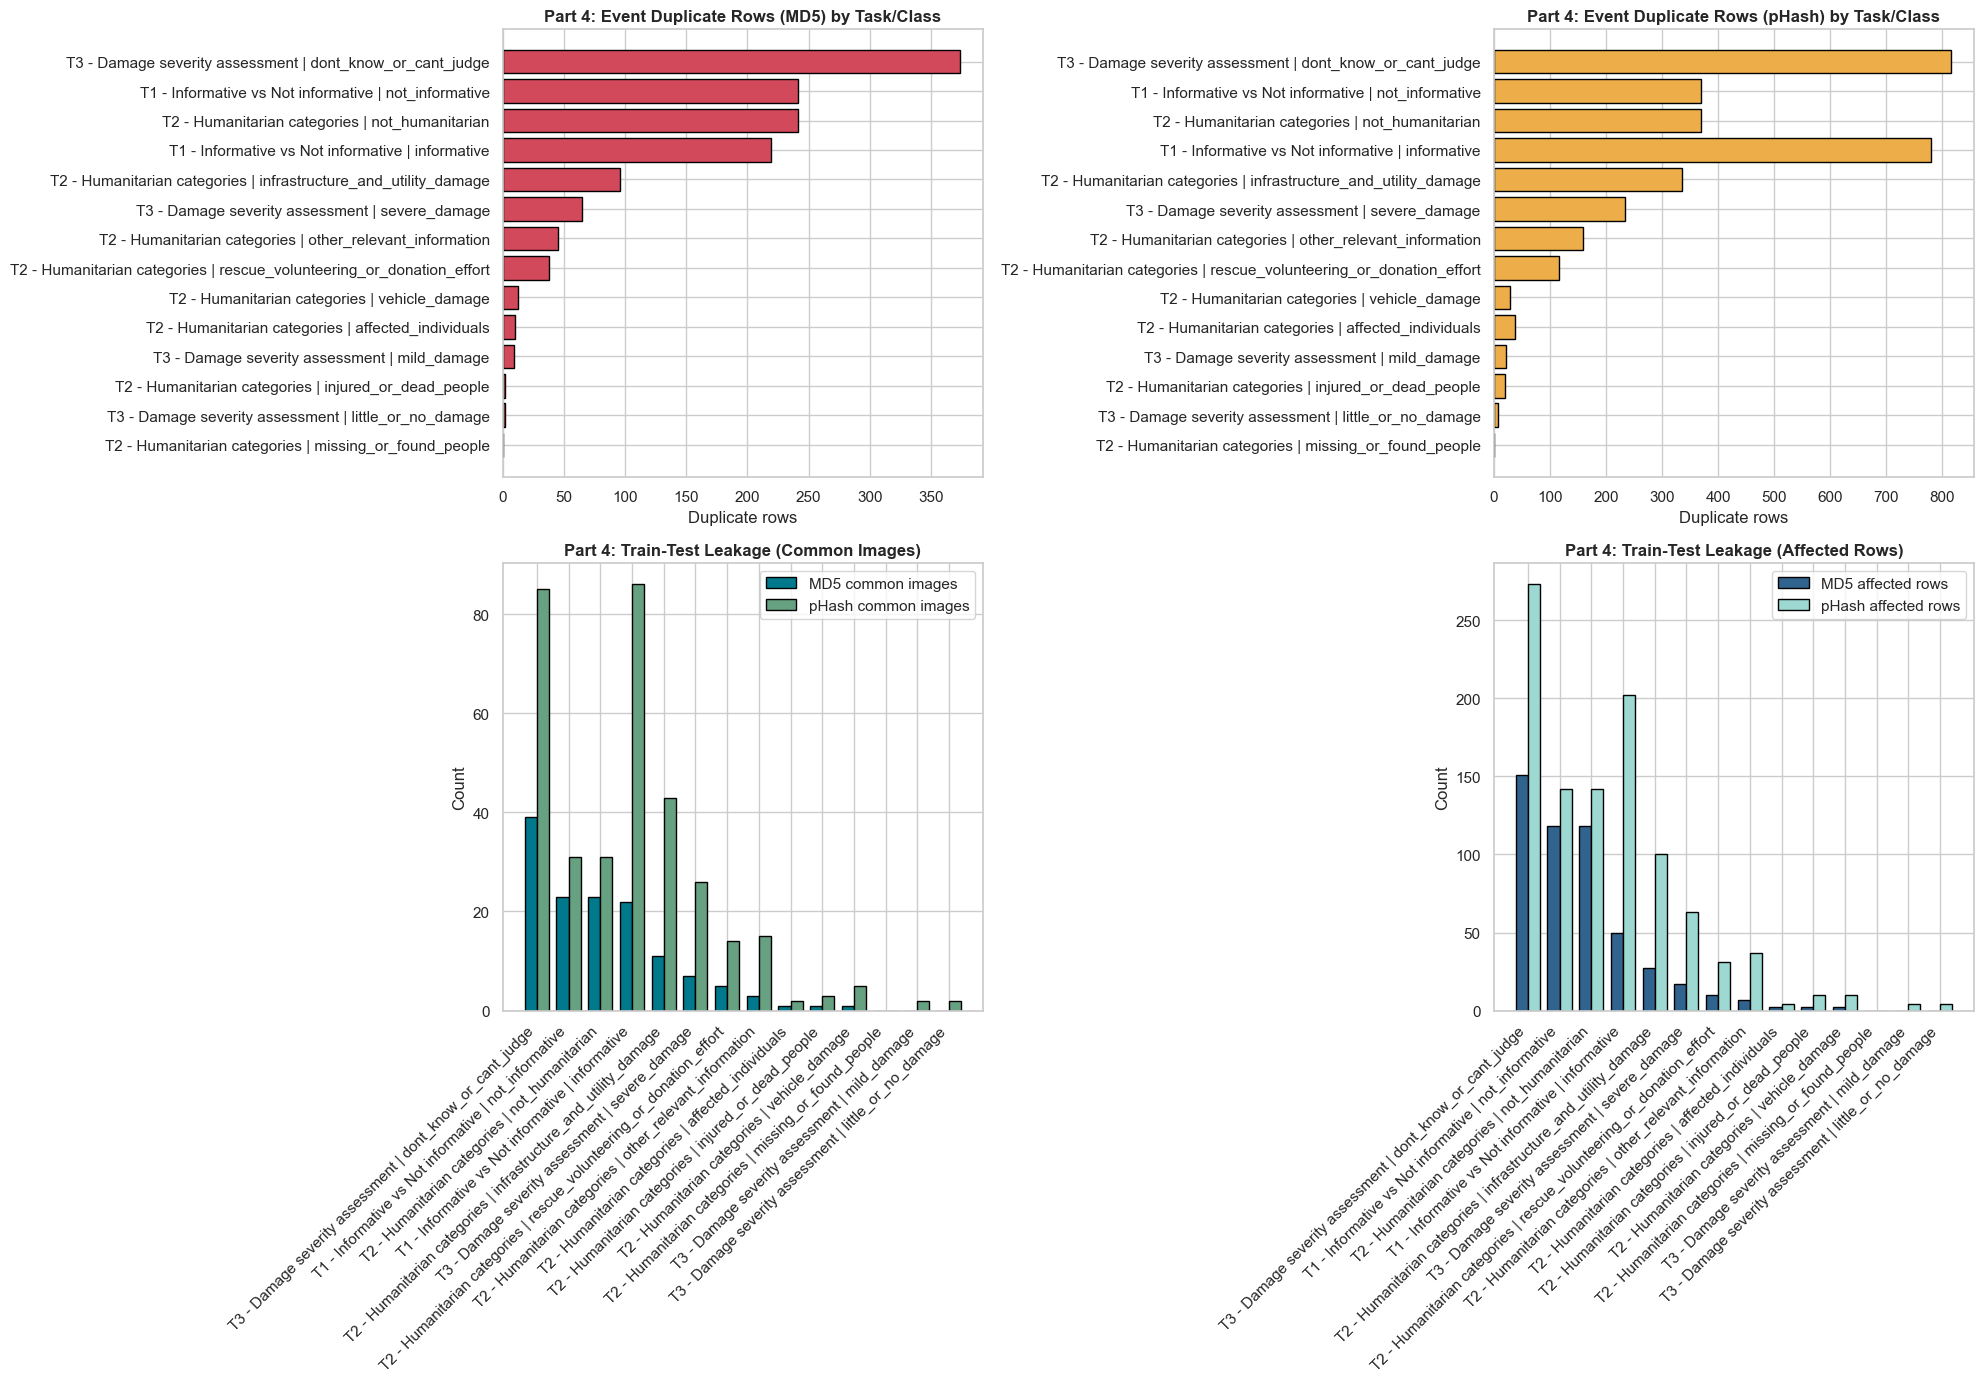

Part 4 chart summary table:
                                   task                                  class  md5_duplicate_rows  phash_duplicate_rows  md5_train_test_common  phash_train_test_common
    Task 3 - Damage severity assessment                dont_know_or_cant_judge                 374                   816                     39                       85
Task 1 - Informative vs Not informative                        not_informative                 241                   369                     23                       31
       Task 2 - Humanitarian categories                       not_humanitarian                 241                   369                     23                       31
Task 1 - Informative vs Not informative                            informative                 219                   780                     22                       86
       Task 2 - Humanitarian categories      infrastructure_and_utility_damage                  96                   336       

In [34]:
# Charts for Part 4: task-wise duplicate totals and train-test leakage
if 'per_task_duplicate_event_tables' not in globals() or 'per_task_leakage_tables' not in globals():
    print("Please run the Part 4 analysis cell first (the cell above this section).")
else:
    # Build compact summary tables from nested Part 4 outputs
    chart_rows = []
    leakage_rows = []

    for task_name, class_map in per_task_duplicate_event_tables.items():
        for class_name, event_df in class_map.items():
            if event_df is None or len(event_df) == 0:
                continue

            chart_rows.append({
                'task': task_name,
                'class': class_name,
                'md5_duplicate_rows': int(event_df['md5_duplicate_rows'].sum()),
                'phash_duplicate_rows': int(event_df['phash_duplicate_rows'].sum()),
                'rows_in_class': int(event_df['rows_in_class'].sum()),
            })

    for task_name, class_map in per_task_leakage_tables.items():
        for class_name, leak_df in class_map.items():
            if leak_df is None or len(leak_df) == 0:
                continue

            train_test = leak_df[leak_df['split_pair'] == 'Train-Test']
            if len(train_test) == 0:
                continue

            leakage_rows.append({
                'task': task_name,
                'class': class_name,
                'md5_train_test_common': int(train_test['md5_common_images'].iloc[0]),
                'phash_train_test_common': int(train_test['phash_common_images'].iloc[0]),
                'md5_train_test_affected': int(train_test['md5_total_affected_rows'].iloc[0]),
                'phash_train_test_affected': int(train_test['phash_total_affected_rows'].iloc[0]),
            })

    summary_df = pd.DataFrame(chart_rows)
    leak_chart_df = pd.DataFrame(leakage_rows)

    if len(summary_df) == 0 or len(leak_chart_df) == 0:
        print("No Part 4 table data available to plot. Re-run the Part 4 analysis cell.")
    else:
        # Keep classes readable in charts
        summary_df['task_class'] = summary_df['task'].str.replace('Task ', 'T', regex=False) + ' | ' + summary_df['class']
        leak_chart_df['task_class'] = leak_chart_df['task'].str.replace('Task ', 'T', regex=False) + ' | ' + leak_chart_df['class']

        summary_df = summary_df.sort_values('md5_duplicate_rows', ascending=False)
        leak_chart_df = leak_chart_df.sort_values('md5_train_test_common', ascending=False)

        fig, axes = plt.subplots(2, 2, figsize=(20, 14))

        # 1) MD5 duplicate rows by task/class
        axes[0, 0].barh(
            summary_df['task_class'],
            summary_df['md5_duplicate_rows'],
            color='#d1495b', edgecolor='black', linewidth=1
        )
        axes[0, 0].set_title('Part 4: Event Duplicate Rows (MD5) by Task/Class', fontweight='bold')
        axes[0, 0].set_xlabel('Duplicate rows')
        axes[0, 0].invert_yaxis()

        # 2) pHash duplicate rows by task/class
        axes[0, 1].barh(
            summary_df['task_class'],
            summary_df['phash_duplicate_rows'],
            color='#edae49', edgecolor='black', linewidth=1
        )
        axes[0, 1].set_title('Part 4: Event Duplicate Rows (pHash) by Task/Class', fontweight='bold')
        axes[0, 1].set_xlabel('Duplicate rows')
        axes[0, 1].invert_yaxis()

        # 3) Train-Test leakage (common images) grouped bars
        x = np.arange(len(leak_chart_df))
        w = 0.38
        axes[1, 0].bar(x - w/2, leak_chart_df['md5_train_test_common'], width=w,
                       label='MD5 common images', color='#00798c', edgecolor='black')
        axes[1, 0].bar(x + w/2, leak_chart_df['phash_train_test_common'], width=w,
                       label='pHash common images', color='#66a182', edgecolor='black')
        axes[1, 0].set_title('Part 4: Train-Test Leakage (Common Images)', fontweight='bold')
        axes[1, 0].set_ylabel('Count')
        axes[1, 0].set_xticks(x)
        axes[1, 0].set_xticklabels(leak_chart_df['task_class'], rotation=45, ha='right')
        axes[1, 0].legend()

        # 4) Train-Test leakage affected rows grouped bars
        axes[1, 1].bar(x - w/2, leak_chart_df['md5_train_test_affected'], width=w,
                       label='MD5 affected rows', color='#30638e', edgecolor='black')
        axes[1, 1].bar(x + w/2, leak_chart_df['phash_train_test_affected'], width=w,
                       label='pHash affected rows', color='#9dd9d2', edgecolor='black')
        axes[1, 1].set_title('Part 4: Train-Test Leakage (Affected Rows)', fontweight='bold')
        axes[1, 1].set_ylabel('Count')
        axes[1, 1].set_xticks(x)
        axes[1, 1].set_xticklabels(leak_chart_df['task_class'], rotation=45, ha='right')
        axes[1, 1].legend()

        plt.tight_layout()
        plt.show()

        # Optional quick table preview for reporting
        display_cols = [
            'task', 'class', 'md5_duplicate_rows', 'phash_duplicate_rows',
            'md5_train_test_common', 'phash_train_test_common'
        ]
        preview = summary_df[['task', 'class', 'md5_duplicate_rows', 'phash_duplicate_rows']].merge(
            leak_chart_df[['task', 'class', 'md5_train_test_common', 'phash_train_test_common']],
            on=['task', 'class'], how='left'
        )
        print('Part 4 chart summary table:')
        print(preview[display_cols].fillna(0).to_string(index=False))

In [51]:
master_df.head()

,tweet_id,image_id,text_info,text_info_conf,image_info,image_info_conf,text_human,text_human_conf,image_human,image_human_conf,image_damage,image_damage_conf,tweet_text,image_url,image_path,disaster_type,image_hash,perceptual_hash,has_phash_duplicate,split
0,917791044158185473,917791044158185473_0,informative,1.0000,informative,0.6766,other_relevant_information,1.0000,other_relevant_information,0.6766,dont_know_or_cant_judge,NaN,RT @Gizmodo: Wildfires raging through Northern...,http://pbs.twimg.com/media/DLyi_WYVYAApwNg.jpg,data_image/california_wildfires/10_10_2017/917...,california_wildfires,eec60f86284d2fc284725b1ce0779a37,86c476bb39c2b16c,False,train
1,917791130590183424,917791130590183424_0,informative,1.0000,informative,0.6667,infrastructure_and_utility_damage,1.0000,affected_individuals,0.6667,dont_know_or_cant_judge,NaN,PHOTOS: Deadly wildfires rage in California ht...,http://pbs.twimg.com/media/DLymKm9UMAAu0qw.jpg,data_image/california_wildfires/10_10_2017/917...,california_wildfires,59d5c08674fe197093ea720fea980b27,f28e9aa98b96a730,True,validation
2,917791291823591425,917791291823591425_0,informative,0.6813,informative,1.0000,other_relevant_information,0.6813,infrastructure_and_utility_damage,1.0000,severe_damage,1.0,RT @Cal_OES: PLS SHARE: Weâ€™re capturing wild...,http://pbs.twimg.com/media/DLudaaZV4AAjT7x.jpg,data_image/california_wildfires/10_10_2017/917...,california_wildfires,2f133fe3e8e9d209b56d0571c1821b02,a9bdb18391838bba,False,train
3,917791291823591425,917791291823591425_1,informative,0.6813,not_informative,1.0000,other_relevant_information,0.6813,not_humanitarian,1.0000,dont_know_or_cant_judge,NaN,RT @Cal_OES: PLS SHARE: Weâ€™re capturing wild...,http://pbs.twimg.com/media/DLudaZXUMAABAEZ.jpg,data_image/california_wildfires/10_10_2017/917...,california_wildfires,b7d6500697eda66c21d0df94cb76c7fb,b582566fab45cac8,False,train
4,917792092100988929,917792092100988929_0,informative,0.6727,informative,0.6612,other_relevant_information,0.6727,infrastructure_and_utility_damage,0.6612,severe_damage,1.0,RT @TIME: California's raging wildfires as you...,http://pbs.twimg.com/media/DLwNe-NXUAE0XCw.jpg,data_image/california_wildfires/10_10_2017/917...,california_wildfires,223b91c2275c977ca8fb8aa11d5969b9,86826be7394ed43a,False,test


In [60]:
# Create a summary table of the damage labels
damage_summary = master_df['image_damage'].value_counts(dropna=False).reset_index()

# Rename columns for clarity
damage_summary.columns = ['Damage Label', 'Total Count']

# Add a percentage column to show the scale of the "NaN" problem
damage_summary['Percentage (%)'] = (damage_summary['Total Count'] / len(master_df) * 100).round(2)

print("--- CRISISMMD IMAGE DAMAGE CATEGORY ANALYSIS ---")
print(damage_summary)

print(f"Total damage images: {master_df[master_df['image_damage'].isin(['severe_damage', 'mild_damage', 'little_or_no_damage'])]['image_damage'].count()}")

--- CRISISMMD IMAGE DAMAGE CATEGORY ANALYSIS ---
              Damage Label  Total Count  Percentage (%)
0  dont_know_or_cant_judge        14556           80.50
1            severe_damage         2212           12.23
2              mild_damage          839            4.64
3      little_or_no_damage          475            2.63
Total damage images: 3526


In [63]:
# 1. Define the damage types we are looking for
target_damages = ['severe_damage', 'mild_damage', 'little_or_no_damage']

# 2. Filter the dataframe to only include these damage types
damage_mask = master_df['image_damage'].isin(target_damages)
damage_only_df = master_df[damage_mask]

# 3. Group by 'image_human' and count the occurrences
humanitarian_counts = damage_only_df['image_human'].value_counts().reset_index()
humanitarian_counts.columns = ['Humanitarian Category', 'Damage Label Count']

# 4. Calculate percentage for the report
total_damage_images = humanitarian_counts['Damage Label Count'].sum()
humanitarian_counts['Percentage (%)'] = (humanitarian_counts['Damage Label Count'] / total_damage_images * 100).round(2)

print(f"Total images analyzed with specific damage labels: {total_damage_images}\n")
print("Distribution of Physical Damage across Humanitarian Categories")
print(humanitarian_counts)

# 5. Logical Verification: Check if any damage exists outside of 'infrastructure'
if len(humanitarian_counts) == 1 and humanitarian_counts.iloc[0]['Humanitarian Category'] == 'infrastructure_and_utility_damage':
    print("\nObservation: 100% of damage labels are locked to the Infrastructure category.")
else:
    print("\nObservation: Damage labels are spread across multiple humanitarian categories.")

Total images analyzed with specific damage labels: 3526

Distribution of Physical Damage across Humanitarian Categories
               Humanitarian Category  Damage Label Count  Percentage (%)
0  infrastructure_and_utility_damage                3526           100.0

Observation: 100% of damage labels are locked to the Infrastructure category.


In [ ]:
master_df.to_csv("CrisisMMD_Master_Processed.tsv", sep='\t', index=False)
print("Phase 1 Complete. Master file saved as 'CrisisMMD_Master_Processed.tsv'")

Phase 1 Complete. Master file saved as 'CrisisMMD_Master_Processed.tsv'
